# 모듈 import 및 사용할 영상 선택

In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"]='4'
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
import h5py
import sys
import cv2
import torch
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
sys.path.append(str(Path("..").joinpath("src").absolute().resolve()))

In [2]:
h5_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data'
subject_lists = sorted( [f for f in os.listdir(h5_dir) ])
subject_number = 2
h_dir = os.path.join(h5_dir,subject_lists[subject_number])
clahe = cv2.createCLAHE(clipLimit=6.0, tileGridSize=(8, 8))

frames_xy = []
frames_clahe_list = []

with h5py.File(h_dir, 'r') as f_r:
    # 데이터셋 키(key) 확인 (파일 안에 어떤 데이터셋이 있는지 모를 때)
    print("Keys in H5 file:", list(f_r.keys()))

    # 'video' 데이터셋의 shape 확인
    if 'video' in f_r:
        video_shape = f_r['video'].shape
        print(f"Video Dataset Shape: {video_shape}")

        # 추가 정보 (자료형 확인)
        print(f"Video Dataset Dtype: {f_r['video'].dtype}")
    else:
        print("'video' key를 찾을 수 없습니다.")

    h5_v = f_r['video']

    print("Converting frames to RGB...")
    for frame in tqdm(h5_v, desc = 'RGB Conversion') :
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_GRAY2RGB)
        frames_xy.append((frame_rgb))

    print("Converting frames to Clahe...")
    for frame in tqdm(h5_v, desc = 'Clahe Conversion') :
        frame_clahe = clahe.apply(frame)
        frame_clahe_rgb = cv2.cvtColor(frame_clahe, cv2.COLOR_GRAY2RGB)
        frames_clahe_list.append(frame_clahe_rgb)

    frames_xy = np.array(frames_xy)
    frames_clahe = np.array(frames_clahe_list)
    del frames_clahe_list

    print(f" 프레임 총 개수 : {len(frames_xy)}, 프레임 shape : {frames_xy[0].shape}")

frames_xy_torch = torch.from_numpy(frames_xy)

num_frames_original = len(frames_xy)

Keys in H5 file: ['video']
Video Dataset Shape: (114422, 220, 350)
Video Dataset Dtype: uint8
Converting frames to RGB...


RGB Conversion:   1%|▏         | 1657/114422 [00:05<06:31, 288.10it/s]


KeyboardInterrupt: 

(107727, 220, 350, 3)


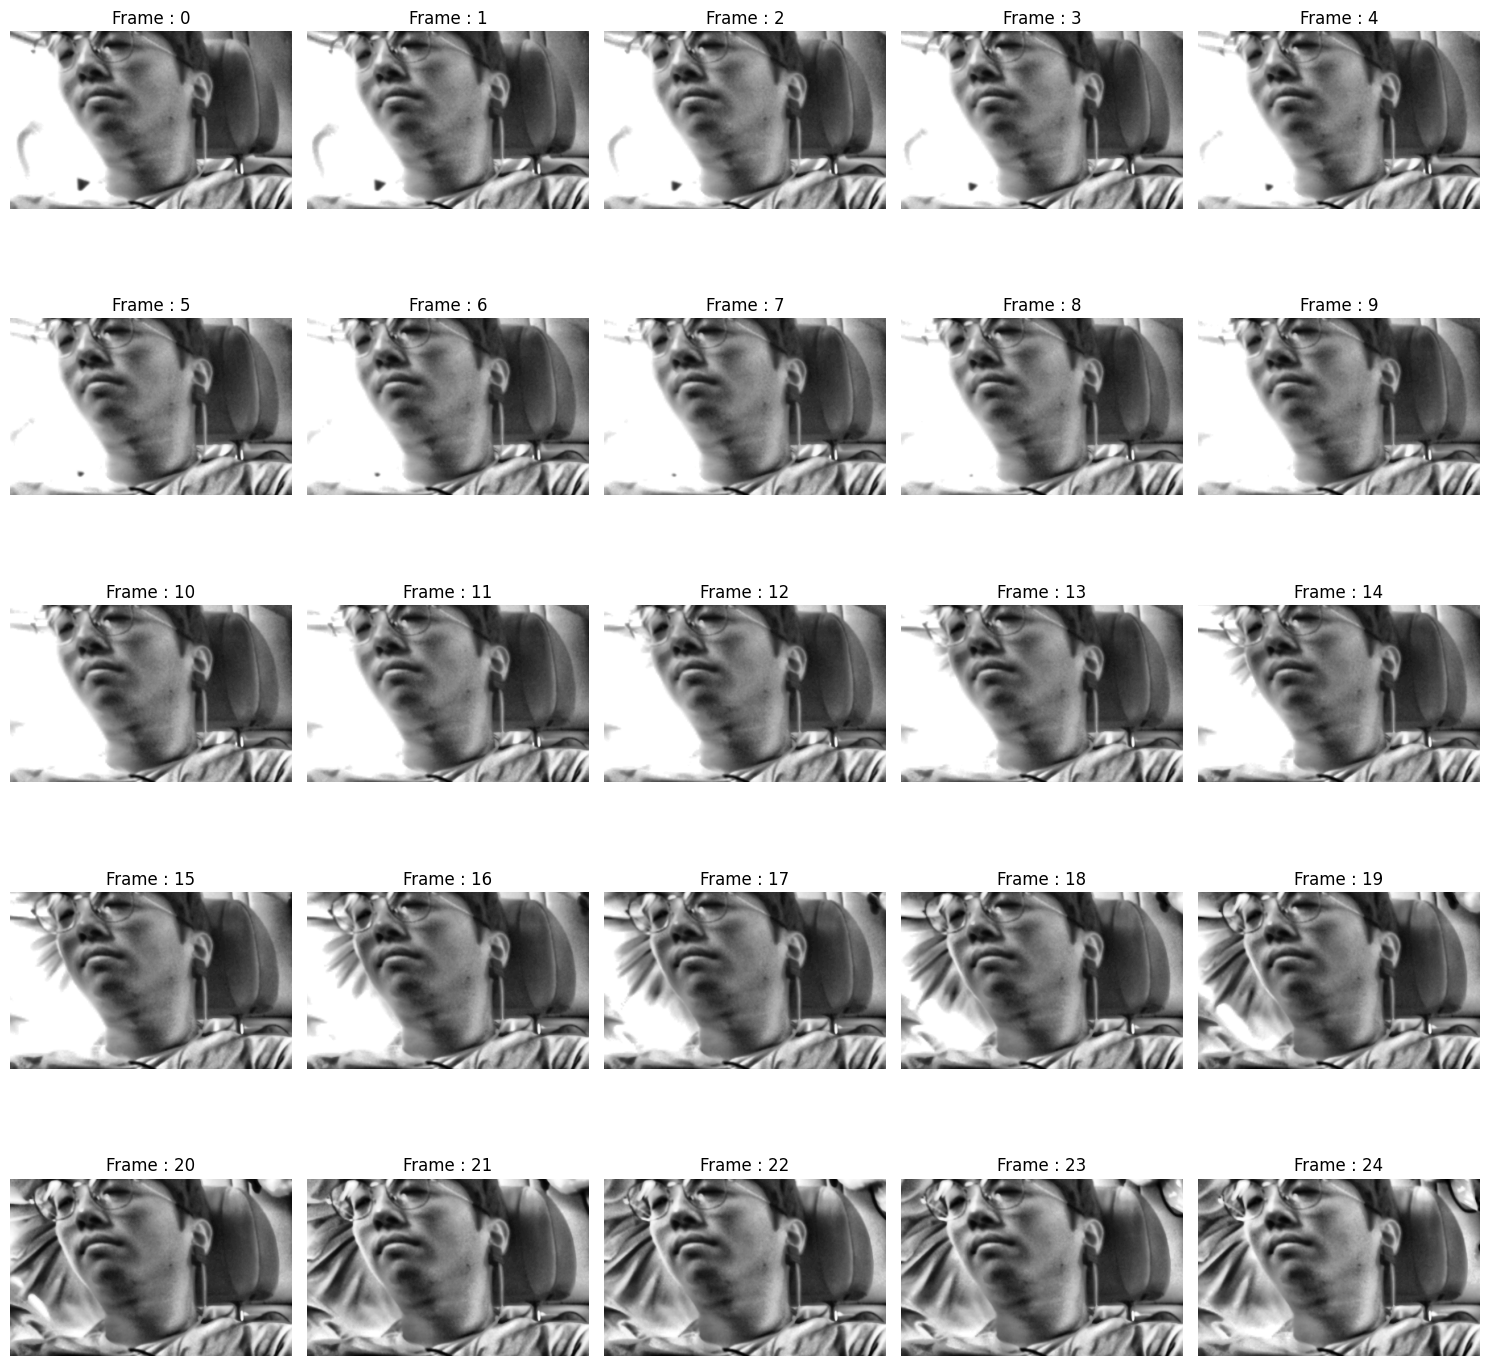

In [147]:
print(frames_xy.shape)
f_ex = frames_clahe[520 : 545]
fig, axes = plt.subplots(5,5, figsize=(15,15)) #fig 가 전체 사진 , axes 가 subplot들 각각 한 칸
axes = axes.flatten()

for i, f in enumerate(f_ex) : 
    axes[i].imshow(f)
    axes[i].set_title(f"Frame : {i}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

# 랜드마크 추출 및 적용확인

In [66]:
import torch
import mediapipe as mp

from torch import Tensor
from typing import Tuple


class MediaPipeLandmarkDetector:
    def __init__(self,
        min_detection_confidence: float = 0.45,
        min_tracking_confidence: float = 0.45,
        device: str = 'cuda' if torch.cuda.is_available() else 'cpu'
    ) -> None:
        self.min_detection_confidence = min_detection_confidence
        self.min_tracking_confidence = min_tracking_confidence
        self.num_landmarks = 468
        self.device = device 

    # 입력 타입을 np.ndarray로 변경
    def __call__(self, frames: np.ndarray) -> tuple[Tensor, Tensor]:
        """
        Args:
            frames (np.ndarray): Video frames of shape [N, H, W, C] (uint8)

        Returns:
            landmarks_tensor (Tensor): [N, 468, 3]
            valid_masks (Tensor): [N]
        """
        landmark_list = []
        valid_list = []

        # frames는 이미 Numpy 배열이므로 shape 바로 접근 가능
        N, H, W, _ = frames.shape

        with mp.solutions.face_mesh.FaceMesh(
            max_num_faces=1,
            static_image_mode=False,
            refine_landmarks=False,
            min_detection_confidence=self.min_detection_confidence,
            min_tracking_confidence=self.min_tracking_confidence,
        ) as face_mesh:
            
            for i in range(N): 
                frame = frames[i] # 여기서 frame은 (H, W, 3)의 Numpy Array

                # MediaPipe는 Numpy Array를 직접 받으므로 변환 불필요
                results = face_mesh.process(frame)

                if results.multi_face_landmarks:
                    face_landmarks = results.multi_face_landmarks[0]
                    
                    # 리스트 컴프리헨션으로 좌표 추출
                    lm_np = np.array([[lm.x * W, lm.y * H, lm.z * W] for lm in face_landmarks.landmark], dtype=np.float32)

                    landmark_list.append(lm_np)
                    valid_list.append(True)
                
                else:
                    # 실패 시 0으로 채운 Numpy 배열 추가 (Tensor 아님)
                    # 나중에 한꺼번에 Tensor로 변환하기 위해 여기서도 Numpy 유지
                    non_face_landmarks = np.zeros((self.num_landmarks, 3), dtype=np.float32)
                    
                    landmark_list.append(non_face_landmarks)
                    valid_list.append(False)
            
            # 1. Numpy 리스트 -> 하나의 Numpy 배열로 변환
            # 2. Numpy 배열 -> Torch Tensor로 변환 및 디바이스 이동
            landmarks_np = np.array(landmark_list)
            
            landmarks_tensor = torch.from_numpy(landmarks_np).to(self.device)
            valid_masks = torch.tensor(valid_list, dtype=torch.bool, device=self.device)

            return landmarks_tensor, valid_masks
            


                

    @property
    def landmarks_uv(self) -> Tensor:
        # 478개 전체 UV 좌표 (MediaPipe Face Mesh Standard)
        MEDIAPIPE_UV_COORDINATES = torch.tensor([
            [0.499976992607117, 0.652534008026123], [0.500025987625122, 0.547487020492554], [0.499974012374878, 0.602371990680695], [0.482113003730774, 0.471979022026062],
            [0.500150978565216, 0.527155995368958], [0.499909996986389, 0.498252987861633], [0.499523013830185, 0.40106201171875], [0.289712011814117, 0.380764007568359],
            [0.499954998493195, 0.312398016452789], [0.499987006187439, 0.269918978214264], [0.500023007392883, 0.107050001621246], [0.500023007392883, 0.666234016418457],
            [0.5000159740448, 0.679224014282227], [0.500023007392883, 0.692348003387451], [0.499976992607117, 0.695277988910675], [0.499976992607117, 0.70593398809433],
            [0.499976992607117, 0.719385027885437], [0.499976992607117, 0.737019002437592], [0.499967992305756, 0.781370997428894], [0.499816000461578, 0.562981009483337],
            [0.473773002624512, 0.573909997940063], [0.104906998574734, 0.254140973091125], [0.365929991006851, 0.409575998783112], [0.338757991790771, 0.41302502155304],
            [0.311120003461838, 0.409460008144379], [0.274657994508743, 0.389131009578705], [0.393361985683441, 0.403706014156342], [0.345234006643295, 0.344011008739471],
            [0.370094001293182, 0.346076011657715], [0.319321990013123, 0.347265005111694], [0.297903001308441, 0.353591024875641], [0.24779200553894, 0.410809993743896],
            [0.396889001131058, 0.842755019664764], [0.280097991228104, 0.375599980354309], [0.106310002505779, 0.399955987930298], [0.2099249958992, 0.391353011131287],
            [0.355807989835739, 0.534406006336212], [0.471751004457474, 0.65040397644043], [0.474155008792877, 0.680191993713379], [0.439785003662109, 0.657229006290436],
            [0.414617002010345, 0.66654098033905], [0.450374007225037, 0.680860996246338], [0.428770989179611, 0.682690978050232], [0.374971002340317, 0.727805018424988],
            [0.486716985702515, 0.547628998756409], [0.485300987958908, 0.527395009994507], [0.257764995098114, 0.314490020275116], [0.401223003864288, 0.455172002315521],
            [0.429818987846375, 0.548614978790283], [0.421351999044418, 0.533740997314453], [0.276895999908447, 0.532056987285614], [0.483370006084442, 0.499586999416351],
            [0.33721199631691, 0.282882988452911], [0.296391993761063, 0.293242990970612], [0.169294998049736, 0.193813979625702], [0.447580009698868, 0.302609980106354],
            [0.392390012741089, 0.353887975215912], [0.354490011930466, 0.696784019470215], [0.067304998636246, 0.730105042457581], [0.442739009857178, 0.572826027870178],
            [0.457098007202148, 0.584792017936707], [0.381974011659622, 0.694710969924927], [0.392388999462128, 0.694203019142151], [0.277076005935669, 0.271932005882263],
            [0.422551989555359, 0.563233017921448], [0.385919004678726, 0.281364023685455], [0.383103013038635, 0.255840003490448], [0.331431001424789, 0.119714021682739],
            [0.229923993349075, 0.232002973556519], [0.364500999450684, 0.189113974571228], [0.229622006416321, 0.299540996551514], [0.173287004232407, 0.278747975826263],
            [0.472878992557526, 0.666198015213013], [0.446828007698059, 0.668527007102966], [0.422762006521225, 0.673889994621277], [0.445307999849319, 0.580065965652466],
            [0.388103008270264, 0.693961024284363], [0.403039008378983, 0.706539988517761], [0.403629004955292, 0.693953037261963], [0.460041999816895, 0.557139039039612],
            [0.431158006191254, 0.692366003990173], [0.452181994915009, 0.692366003990173], [0.475387006998062, 0.692366003990173], [0.465828001499176, 0.779190003871918],
            [0.472328990697861, 0.736225962638855], [0.473087012767792, 0.717857003211975], [0.473122000694275, 0.704625964164734], [0.473033010959625, 0.695277988910675],
            [0.427942007780075, 0.695277988910675], [0.426479011774063, 0.703539967536926], [0.423162013292313, 0.711845993995667], [0.4183090031147, 0.720062971115112],
            [0.390094995498657, 0.639572978019714], [0.013953999616206, 0.560034036636353], [0.499913990497589, 0.58014702796936], [0.413199990987778, 0.69539999961853],
            [0.409626007080078, 0.701822996139526], [0.468080013990402, 0.601534962654114], [0.422728985548019, 0.585985004901886], [0.463079988956451, 0.593783974647522],
            [0.37211999297142, 0.47341400384903], [0.334562003612518, 0.496073007583618], [0.411671012639999, 0.546965003013611], [0.242175996303558, 0.14767599105835],
            [0.290776997804642, 0.201445996761322], [0.327338010072708, 0.256527006626129], [0.399509996175766, 0.748921036720276], [0.441727995872498, 0.261676013469696],
            [0.429764986038208, 0.187834024429321], [0.412198007106781, 0.108901023864746], [0.288955003023148, 0.398952007293701], [0.218936994671822, 0.435410976409912],
            [0.41278201341629, 0.398970007896423], [0.257135003805161, 0.355440020561218], [0.427684992551804, 0.437960982322693], [0.448339998722076, 0.536936044692993],
            [0.178560003638268, 0.45755398273468], [0.247308000922203, 0.457193970680237], [0.286267012357712, 0.467674970626831], [0.332827985286713, 0.460712015628815],
            [0.368755996227264, 0.447206974029541], [0.398963987827301, 0.432654976844788], [0.476410001516342, 0.405806005001068], [0.189241006970406, 0.523923993110657],
            [0.228962004184723, 0.348950982093811], [0.490725994110107, 0.562400996685028], [0.404670000076294, 0.485132992267609], [0.019469000399113, 0.401564002037048],
            [0.426243007183075, 0.420431017875671], [0.396993011236191, 0.548797011375427], [0.266469985246658, 0.376977026462555], [0.439121007919312, 0.51895797252655],
            [0.032313998788595, 0.644356966018677], [0.419054001569748, 0.387154996395111], [0.462783008813858, 0.505746960639954], [0.238978996872902, 0.779744982719421],
            [0.198220998048782, 0.831938028335571], [0.107550002634525, 0.540755033493042], [0.183610007166862, 0.740257024765015], [0.134409993886948, 0.333683013916016],
            [0.385764002799988, 0.883153975009918], [0.490967005491257, 0.579378008842468], [0.382384985685349, 0.508572995662689], [0.174399003386497, 0.397670984268188],
            [0.318785011768341, 0.39623498916626], [0.343364000320435, 0.400596976280212], [0.396100014448166, 0.710216999053955], [0.187885001301765, 0.588537991046906],
            [0.430987000465393, 0.944064974784851], [0.318993002176285, 0.898285031318665], [0.266247987747192, 0.869701027870178], [0.500023007392883, 0.190576016902924],
            [0.499976992607117, 0.954452991485596], [0.366169989109039, 0.398822009563446], [0.393207013607025, 0.39553701877594], [0.410373002290726, 0.391080021858215],
            [0.194993004202843, 0.342101991176605], [0.388664990663528, 0.362284004688263], [0.365961998701096, 0.355970978736877], [0.343364000320435, 0.355356991291046],
            [0.318785011768341, 0.35834002494812], [0.301414996385574, 0.363156020641327], [0.058132998645306, 0.319076001644135], [0.301414996385574, 0.387449026107788],
            [0.499987989664078, 0.618434011936188], [0.415838003158569, 0.624195992946625], [0.445681989192963, 0.566076993942261], [0.465844005346298, 0.620640993118286],
            [0.49992299079895, 0.351523995399475], [0.288718998432159, 0.819945991039276], [0.335278987884521, 0.852819979190826], [0.440512001514435, 0.902418971061707],
            [0.128294005990028, 0.791940987110138], [0.408771991729736, 0.373893976211548], [0.455606997013092, 0.451801002025604], [0.499877005815506, 0.908990025520325],
            [0.375436991453171, 0.924192011356354], [0.11421000212431, 0.615022003650665], [0.448662012815475, 0.695277988910675], [0.4480200111866, 0.704632043838501],
            [0.447111994028091, 0.715808033943176], [0.444831997156143, 0.730794012546539], [0.430011987686157, 0.766808986663818], [0.406787008047104, 0.685672998428345],
            [0.400738000869751, 0.681069016456604], [0.392399996519089, 0.677703022956848], [0.367855995893478, 0.663918972015381], [0.247923001646996, 0.601333022117615],
            [0.452769994735718, 0.420849978923798], [0.43639200925827, 0.359887003898621], [0.416164010763168, 0.368713974952698], [0.413385987281799, 0.692366003990173],
            [0.228018000721931, 0.683571994304657], [0.468268007040024, 0.352671027183533], [0.411361992359161, 0.804327011108398], [0.499989002943039, 0.469825029373169],
            [0.479153990745544, 0.442654013633728], [0.499974012374878, 0.439637005329132], [0.432112008333206, 0.493588984012604], [0.499886006116867, 0.866917014122009],
            [0.49991300702095, 0.821729004383087], [0.456548988819122, 0.819200992584229], [0.344549000263214, 0.745438992977142], [0.37890899181366, 0.574010014533997],
            [0.374292999505997, 0.780184984207153], [0.319687992334366, 0.570737957954407], [0.357154995203018, 0.604269981384277], [0.295284003019333, 0.621580958366394],
            [0.447750002145767, 0.862477004528046], [0.410986006259918, 0.508723020553589], [0.31395098567009, 0.775308012962341], [0.354128003120422, 0.812552988529205],
            [0.324548006057739, 0.703992962837219], [0.189096003770828, 0.646299958229065], [0.279776990413666, 0.71465802192688], [0.1338230073452, 0.682700991630554],
            [0.336768001317978, 0.644733011722565], [0.429883986711502, 0.466521978378296], [0.455527991056442, 0.548622965812683], [0.437114000320435, 0.558896005153656],
            [0.467287987470627, 0.529924988746643], [0.414712011814117, 0.335219979286194], [0.37704598903656, 0.322777986526489], [0.344107985496521, 0.320150971412659],
            [0.312875986099243, 0.32233202457428], [0.283526003360748, 0.333190023899078], [0.241245999932289, 0.382785975933075], [0.102986000478268, 0.468762993812561],
            [0.267612010240555, 0.424560010433197], [0.297879010438919, 0.433175981044769], [0.333433985710144, 0.433878004550934], [0.366427004337311, 0.426115989685059],
            [0.396012008190155, 0.416696012020111], [0.420121014118195, 0.41022801399231], [0.007561000064015, 0.480777025222778], [0.432949006557465, 0.569517970085144],
            [0.458638995885849, 0.479089021682739], [0.473466008901596, 0.545744001865387], [0.476087987422943, 0.563830018043518], [0.468472003936768, 0.555056989192963],
            [0.433990985155106, 0.582361996173859], [0.483518004417419, 0.562983989715576], [0.482482999563217, 0.57784903049469], [0.42645001411438, 0.389798998832703],
            [0.438998997211456, 0.39649498462677], [0.450067013502121, 0.400434017181396], [0.289712011814117, 0.368252992630005], [0.276670008897781, 0.363372981548309],
            [0.517862021923065, 0.471948027610779], [0.710287988185883, 0.380764007568359], [0.526226997375488, 0.573909997940063], [0.895093023777008, 0.254140973091125],
            [0.634069979190826, 0.409575998783112], [0.661242008209229, 0.41302502155304], [0.688880026340485, 0.409460008144379], [0.725341975688934, 0.389131009578705],
            [0.606630027294159, 0.40370500087738], [0.654766023159027, 0.344011008739471], [0.629905998706818, 0.346076011657715], [0.680678009986877, 0.347265005111694],
            [0.702096998691559, 0.353591024875641], [0.75221198797226, 0.410804986953735], [0.602918028831482, 0.842862963676453], [0.719901978969574, 0.375599980354309],
            [0.893692970275879, 0.399959981441498], [0.790081977844238, 0.391354024410248], [0.643998026847839, 0.534487962722778], [0.528249025344849, 0.65040397644043],
            [0.525849997997284, 0.680191040039062], [0.560214996337891, 0.657229006290436], [0.585384011268616, 0.66654098033905], [0.549625992774963, 0.680860996246338],
            [0.57122802734375, 0.682691991329193], [0.624852001667023, 0.72809898853302], [0.513050019741058, 0.547281980514526], [0.51509702205658, 0.527251958847046],
            [0.742246985435486, 0.314507007598877], [0.598631024360657, 0.454979002475739], [0.570338010787964, 0.548575043678284], [0.578631997108459, 0.533622980117798],
            [0.723087012767792, 0.532054007053375], [0.516445994377136, 0.499638974666595], [0.662801027297974, 0.282917976379395], [0.70362401008606, 0.293271005153656],
            [0.830704987049103, 0.193813979625702], [0.552385985851288, 0.302568018436432], [0.607609987258911, 0.353887975215912], [0.645429015159607, 0.696707010269165],
            [0.932694971561432, 0.730105042457581], [0.557260990142822, 0.572826027870178], [0.542901992797852, 0.584792017936707], [0.6180260181427, 0.694710969924927],
            [0.607590973377228, 0.694203019142151], [0.722943007946014, 0.271963000297546], [0.577413976192474, 0.563166975975037], [0.614082992076874, 0.281386971473694],
            [0.616907000541687, 0.255886018276215], [0.668509006500244, 0.119913995265961], [0.770092010498047, 0.232020974159241], [0.635536015033722, 0.189248979091644],
            [0.77039098739624, 0.299556016921997], [0.826722025871277, 0.278755009174347], [0.527121007442474, 0.666198015213013], [0.553171992301941, 0.668527007102966],
            [0.577238023281097, 0.673889994621277], [0.554691970348358, 0.580065965652466], [0.611896991729736, 0.693961024284363], [0.59696102142334, 0.706539988517761],
            [0.596370995044708, 0.693953037261963], [0.539958000183105, 0.557139039039612], [0.568841993808746, 0.692366003990173], [0.547818005084991, 0.692366003990173],
            [0.52461302280426, 0.692366003990173], [0.534089982509613, 0.779141008853912], [0.527670979499817, 0.736225962638855], [0.526912987232208, 0.717857003211975],
            [0.526877999305725, 0.704625964164734], [0.526966989040375, 0.695277988910675], [0.572058022022247, 0.695277988910675], [0.573521018028259, 0.703539967536926],
            [0.57683801651001, 0.711845993995667], [0.581691026687622, 0.720062971115112], [0.609944999217987, 0.639909982681274], [0.986046016216278, 0.560034036636353],
            [0.5867999792099, 0.69539999961853], [0.590372025966644, 0.701822996139526], [0.531915009021759, 0.601536989212036], [0.577268004417419, 0.585934996604919],
            [0.536915004253387, 0.593786001205444], [0.627542972564697, 0.473352015018463], [0.665585994720459, 0.495950996875763], [0.588353991508484, 0.546862006187439],
            [0.757824003696442, 0.14767599105835], [0.709249973297119, 0.201507985591888], [0.672684013843536, 0.256581008434296], [0.600408971309662, 0.74900496006012],
            [0.55826598405838, 0.261672019958496], [0.570303976535797, 0.187870979309082], [0.588165998458862, 0.109044015407562], [0.711045026779175, 0.398952007293701],
            [0.781069993972778, 0.435405015945435], [0.587247014045715, 0.398931980133057], [0.742869973182678, 0.355445981025696], [0.572156012058258, 0.437651991844177],
            [0.55186802148819, 0.536570012569427], [0.821442008018494, 0.457556009292603], [0.752701997756958, 0.457181990146637], [0.71375697851181, 0.467626988887787],
            [0.66711300611496, 0.460672974586487], [0.631101012229919, 0.447153985500336], [0.6008620262146, 0.432473003864288], [0.523481011390686, 0.405627012252808],
            [0.810747981071472, 0.523926019668579], [0.771045982837677, 0.348959028720856], [0.509127020835876, 0.562718033790588], [0.595292985439301, 0.485023975372314],
            [0.980530977249146, 0.401564002037048], [0.573499977588654, 0.420000016689301], [0.602994978427887, 0.548687994480133], [0.733529984951019, 0.376977026462555],
            [0.560611009597778, 0.519016981124878], [0.967685997486115, 0.644356966018677], [0.580985009670258, 0.387160003185272], [0.537728011608124, 0.505385041236877],
            [0.760966002941132, 0.779752969741821], [0.801778972148895, 0.831938028335571], [0.892440974712372, 0.54076099395752], [0.816350996494293, 0.740260004997253],
            [0.865594983100891, 0.333687007427216], [0.614073991775513, 0.883246004581451], [0.508952975273132, 0.579437971115112], [0.617941975593567, 0.508316040039062],
            [0.825608015060425, 0.397674977779388], [0.681214988231659, 0.39623498916626], [0.656635999679565, 0.400596976280212], [0.603900015354156, 0.710216999053955],
            [0.81208598613739, 0.588539004325867], [0.56801301240921, 0.944564998149872], [0.681007981300354, 0.898285031318665], [0.733752012252808, 0.869701027870178],
            [0.633830010890961, 0.398822009563446], [0.606792986392975, 0.39553701877594], [0.589659988880157, 0.391062021255493], [0.805015981197357, 0.342108011245728],
            [0.611334979534149, 0.362284004688263], [0.634037971496582, 0.355970978736877], [0.656635999679565, 0.355356991291046], [0.681214988231659, 0.35834002494812],
            [0.698584973812103, 0.363156020641327], [0.941866993904114, 0.319076001644135], [0.698584973812103, 0.387449026107788], [0.584177017211914, 0.624107003211975],
            [0.554318010807037, 0.566076993942261], [0.534153997898102, 0.62064003944397], [0.711217999458313, 0.819975018501282], [0.664629995822906, 0.852871000766754],
            [0.559099972248077, 0.902631998062134], [0.871706008911133, 0.791940987110138], [0.591234028339386, 0.373893976211548], [0.544341027736664, 0.451583981513977],
            [0.624562978744507, 0.924192011356354], [0.88577002286911, 0.615028977394104], [0.551338016986847, 0.695277988910675], [0.551980018615723, 0.704632043838501],
            [0.552887976169586, 0.715808033943176], [0.555167973041534, 0.730794012546539], [0.569944024085999, 0.767035007476807], [0.593203008174896, 0.685675978660583],
            [0.599261999130249, 0.681069016456604], [0.607599973678589, 0.677703022956848], [0.631937980651855, 0.663500010967255], [0.752032995223999, 0.601315021514893],
            [0.547226011753082, 0.420395016670227], [0.563543975353241, 0.359827995300293], [0.583841025829315, 0.368713974952698], [0.586614012718201, 0.692366003990173],
            [0.771915018558502, 0.683578014373779], [0.531597018241882, 0.352482974529266], [0.588370978832245, 0.804440975189209], [0.52079701423645, 0.442565023899078],
            [0.567984998226166, 0.493479013442993], [0.543282985687256, 0.819254994392395], [0.655317008495331, 0.745514988899231], [0.621008992195129, 0.574018001556396],
            [0.625559985637665, 0.78031200170517], [0.680198013782501, 0.570719003677368], [0.64276397228241, 0.604337990283966], [0.704662978649139, 0.621529996395111],
            [0.552012026309967, 0.862591981887817], [0.589071989059448, 0.508637011051178], [0.685944974422455, 0.775357007980347], [0.645735025405884, 0.812640011310577],
            [0.675342977046967, 0.703978002071381], [0.810858011245728, 0.646304965019226], [0.72012197971344, 0.714666962623596], [0.866151988506317, 0.682704985141754],
            [0.663187026977539, 0.644596993923187], [0.570082008838654, 0.466325998306274], [0.544561982154846, 0.548375964164734], [0.562758982181549, 0.558784961700439],
            [0.531987011432648, 0.530140042304993], [0.585271000862122, 0.335177004337311], [0.622952997684479, 0.32277899980545], [0.655896008014679, 0.320163011550903],
            [0.687132000923157, 0.322345972061157], [0.716481983661652, 0.333200991153717], [0.758756995201111, 0.382786989212036], [0.897013008594513, 0.468769013881683],
            [0.732392013072968, 0.424547016620636], [0.70211398601532, 0.433162987232208], [0.66652500629425, 0.433866024017334], [0.633504986763, 0.426087975502014],
            [0.603875994682312, 0.416586995124817], [0.579657971858978, 0.409945011138916], [0.992439985275269, 0.480777025222778], [0.567192018032074, 0.569419980049133],
            [0.54136598110199, 0.478899002075195], [0.526564002037048, 0.546118021011353], [0.523913025856018, 0.563830018043518], [0.531529009342194, 0.555056989192963],
            [0.566035985946655, 0.582329034805298], [0.51631098985672, 0.563053965568542], [0.5174720287323, 0.577877044677734], [0.573594987392426, 0.389806985855103],
            [0.560697972774506, 0.395331978797913], [0.549755990505219, 0.399751007556915], [0.710287988185883, 0.368252992630005], [0.723330020904541, 0.363372981548309],
        ], dtype=torch.float32)
        return MEDIAPIPE_UV_COORDINATES

    @property
    def mesh_tesselation(self) -> Tensor:
        MEDIAPIPE_MESH_TESSELLATION = torch.tensor([
            (127, 34),  (34, 139),  (139, 127), (11, 0),    (0, 37),    (37, 11),   (232, 231), (231, 120), (120, 232), (72, 37),   (37, 39),   (39, 72),
            (128, 121), (121, 47),  (47, 128),  (232, 121), (121, 128), (128, 232), (104, 69),  (69, 67),   (67, 104),  (175, 171), (171, 148), (148, 175),
            (118, 50),  (50, 101),  (101, 118), (73, 39),   (39, 40),   (40, 73),   (9, 151),   (151, 108), (108, 9),   (48, 115),  (115, 131), (131, 48),
            (194, 204), (204, 211), (211, 194), (74, 40),   (40, 185),  (185, 74),  (80, 42),   (42, 183),  (183, 80),  (40, 92),   (92, 186),  (186, 40),
            (230, 229), (229, 118), (118, 230), (202, 212), (212, 214), (214, 202), (83, 18),   (18, 17),   (17, 83),   (76, 61),   (61, 146),  (146, 76),
            (160, 29),  (29, 30),   (30, 160),  (56, 157),  (157, 173), (173, 56),  (106, 204), (204, 194), (194, 106), (135, 214), (214, 192), (192, 135),
            (203, 165), (165, 98),  (98, 203),  (21, 71),   (71, 68),   (68, 21),   (51, 45),   (45, 4),    (4, 51),    (144, 24),  (24, 23),   (23, 144),
            (77, 146),  (146, 91),  (91, 77),   (205, 50),  (50, 187),  (187, 205), (201, 200), (200, 18),  (18, 201),  (91, 106),  (106, 182), (182, 91),
            (90, 91),   (91, 181),  (181, 90),  (85, 84),   (84, 17),   (17, 85),   (206, 203), (203, 36),  (36, 206),  (148, 171), (171, 140), (140, 148),
            (92, 40),   (40, 39),   (39, 92),   (193, 189), (189, 244), (244, 193), (159, 158), (158, 28),  (28, 159),  (247, 246), (246, 161), (161, 247),
            (236, 3),   (3, 196),   (196, 236), (54, 68),   (68, 104),  (104, 54),  (193, 168), (168, 8),   (8, 193),   (117, 228), (228, 31),  (31, 117),
            (189, 193), (193, 55),  (55, 189),  (98, 97),   (97, 99),   (99, 98),   (126, 47),  (47, 100),  (100, 126), (166, 79),  (79, 218),  (218, 166),
            (155, 154), (154, 26),  (26, 155),  (209, 49),  (49, 131),  (131, 209), (135, 136), (136, 150), (150, 135), (47, 126),  (126, 217), (217, 47),
            (223, 52),  (52, 53),   (53, 223),  (45, 51),   (51, 134),  (134, 45),  (211, 170), (170, 140), (140, 211), (67, 69),   (69, 108),  (108, 67),
            (43, 106),  (106, 91),  (91, 43),   (230, 119), (119, 120), (120, 230), (226, 130), (130, 247), (247, 226), (63, 53),   (53, 52),   (52, 63),
            (238, 20),  (20, 242),  (242, 238), (46, 70),   (70, 156),  (156, 46),  (78, 62),   (62, 96),   (96, 78),   (46, 53),   (53, 63),   (63, 46),
            (143, 34),  (34, 227),  (227, 143), (123, 117), (117, 111), (111, 123), (44, 125),  (125, 19),  (19, 44),   (236, 134), (134, 51),  (51, 236),
            (216, 206), (206, 205), (205, 216), (154, 153), (153, 22),  (22, 154),  (39, 37),   (37, 167),  (167, 39),  (200, 201), (201, 208), (208, 200),
            (36, 142),  (142, 100), (100, 36),  (57, 212),  (212, 202), (202, 57),  (20, 60),   (60, 99),   (99, 20),   (28, 158),  (158, 157), (157, 28),
            (35, 226),  (226, 113), (113, 35),  (160, 159), (159, 27),  (27, 160),  (204, 202), (202, 210), (210, 204), (113, 225), (225, 46),  (46, 113),
            (43, 202),  (202, 204), (204, 43),  (62, 76),   (76, 77),   (77, 62),   (137, 123), (123, 116), (116, 137), (41, 38),   (38, 72),   (72, 41),
            (203, 129), (129, 142), (142, 203), (64, 98),   (98, 240),  (240, 64),  (49, 102),  (102, 64),  (64, 49),   (41, 73),   (73, 74),   (74, 41),
            (212, 216), (216, 207), (207, 212), (42, 74),   (74, 184),  (184, 42),  (169, 170), (170, 211), (211, 169), (170, 149), (149, 176), (176, 170),
            (105, 66),  (66, 69),   (69, 105),  (122, 6),   (6, 168),   (168, 122), (123, 147), (147, 187), (187, 123), (96, 77),   (77, 90),   (90, 96),
            (65, 55),   (55, 107),  (107, 65),  (89, 90),   (90, 180),  (180, 89),  (101, 100), (100, 120), (120, 101), (63, 105),  (105, 104), (104, 63),
            (93, 137),  (137, 227), (227, 93),  (15, 86),   (86, 85),   (85, 15),   (129, 102), (102, 49),  (49, 129),  (14, 87),   (87, 86),   (86, 14),
            (55, 8),    (8, 9),     (9, 55),    (100, 47),  (47, 121),  (121, 100), (145, 23),  (23, 22),   (22, 145),  (88, 89),   (89, 179),  (179, 88),
            (6, 122),   (122, 196), (196, 6),   (88, 95),   (95, 96),   (96, 88),   (138, 172), (172, 136), (136, 138), (215, 58),  (58, 172),  (172, 215),
            (115, 48),  (48, 219),  (219, 115), (42, 80),   (80, 81),   (81, 42),   (195, 3),   (3, 51),    (51, 195),  (43, 146),  (146, 61),  (61, 43),
            (171, 175), (175, 199), (199, 171), (81, 82),   (82, 38),   (38, 81),   (53, 46),   (46, 225),  (225, 53),  (144, 163), (163, 110), (110, 144),
            (52, 65),   (65, 66),   (66, 52),   (229, 228), (228, 117), (117, 229), (34, 127),  (127, 234), (234, 34),  (107, 108), (108, 69),  (69, 107),
            (109, 108), (108, 151), (151, 109), (48, 64),   (64, 235),  (235, 48),  (62, 78),   (78, 191),  (191, 62),  (129, 209), (209, 126), (126, 129),
            (111, 35),  (35, 143),  (143, 111), (117, 123), (123, 50),  (50, 117),  (222, 65),  (65, 52),   (52, 222),  (19, 125),  (125, 141), (141, 19),
            (221, 55),  (55, 65),   (65, 221),  (3, 195),   (195, 197), (197, 3),   (25, 7),    (7, 33),    (33, 25),   (220, 237), (237, 44),  (44, 220),
            (70, 71),   (71, 139),  (139, 70),  (122, 193), (193, 245), (245, 122), (247, 130), (130, 33),  (33, 247),  (71, 21),   (21, 162),  (162, 71),
            (170, 169), (169, 150), (150, 170), (188, 174), (174, 196), (196, 188), (216, 186), (186, 92),  (92, 216),  (2, 97),    (97, 167),  (167, 2),
            (141, 125), (125, 241), (241, 141), (164, 167), (167, 37),  (37, 164),  (72, 38),   (38, 12),   (12, 72),   (38, 82),   (82, 13),   (13, 38),
            (63, 68),   (68, 71),   (71, 63),   (226, 35),  (35, 111),  (111, 226), (101, 50),  (50, 205),  (205, 101), (206, 92),  (92, 165),  (165, 206),
            (209, 198), (198, 217), (217, 209), (165, 167), (167, 97),  (97, 165),  (220, 115), (115, 218), (218, 220), (133, 112), (112, 243), (243, 133),
            (239, 238), (238, 241), (241, 239), (214, 135), (135, 169), (169, 214), (190, 173), (173, 133), (133, 190), (171, 208), (208, 32),  (32, 171),
            (125, 44),  (44, 237),  (237, 125), (86, 87),   (87, 178),  (178, 86),  (85, 86),   (86, 179),  (179, 85),  (84, 85),   (85, 180),  (180, 84),
            (83, 84),   (84, 181),  (181, 83),  (201, 83),  (83, 182),  (182, 201), (137, 93),  (93, 132),  (132, 137), (76, 62),   (62, 183),  (183, 76),
            (61, 76),   (76, 184),  (184, 61),  (57, 61),   (61, 185),  (185, 57),  (212, 57),  (57, 186),  (186, 212), (214, 207), (207, 187), (187, 214),
            (34, 143),  (143, 156), (156, 34),  (79, 239),  (239, 237), (237, 79),  (123, 137), (137, 177), (177, 123), (44, 1),    (1, 4),     (4, 44),
            (201, 194), (194, 32),  (32, 201),  (64, 102),  (102, 129), (129, 64),  (213, 215), (215, 138), (138, 213), (59, 166),  (166, 219), (219, 59),
            (242, 99),  (99, 97),   (97, 242),  (2, 94),    (94, 141),  (141, 2),   (75, 59),   (59, 235),  (235, 75),  (24, 110),  (110, 228), (228, 24),
            (25, 130),  (130, 226), (226, 25),  (23, 24),   (24, 229),  (229, 23),  (22, 23),   (23, 230),  (230, 22),  (26, 22),   (22, 231),  (231, 26),
            (112, 26),  (26, 232),  (232, 112), (189, 190), (190, 243), (243, 189), (221, 56),  (56, 190),  (190, 221), (28, 56),   (56, 221),  (221, 28),
            (27, 28),   (28, 222),  (222, 27),  (29, 27),   (27, 223),  (223, 29),  (30, 29),   (29, 224),  (224, 30),  (247, 30),  (30, 225),  (225, 247),
            (238, 79),  (79, 20),   (20, 238),  (166, 59),  (59, 75),   (75, 166),  (60, 75),   (75, 240),  (240, 60),  (147, 177), (177, 215), (215, 147),
            (20, 79),   (79, 166),  (166, 20),  (187, 147), (147, 213), (213, 187), (112, 233), (233, 244), (244, 112), (233, 128), (128, 245), (245, 233),
            (128, 114), (114, 188), (188, 128), (114, 217), (217, 174), (174, 114), (131, 115), (115, 220), (220, 131), (217, 198), (198, 236), (236, 217),
            (198, 131), (131, 134), (134, 198), (177, 132), (132, 58),  (58, 177),  (143, 35),  (35, 124),  (124, 143), (110, 163), (163, 7),   (7, 110),
            (228, 110), (110, 25),  (25, 228),  (356, 389), (389, 368), (368, 356), (11, 302),  (302, 267), (267, 11),  (452, 350), (350, 349), (349, 452),
            (302, 303), (303, 269), (269, 302), (357, 343), (343, 277), (277, 357), (452, 453), (453, 357), (357, 452), (333, 332), (332, 297), (297, 333),
            (175, 152), (152, 377), (377, 175), (347, 348), (348, 330), (330, 347), (303, 304), (304, 270), (270, 303), (9, 336),   (336, 337), (337, 9),
            (278, 279), (279, 360), (360, 278), (418, 262), (262, 431), (431, 418), (304, 408), (408, 409), (409, 304), (310, 415), (415, 407), (407, 310),
            (270, 409), (409, 410), (410, 270), (450, 348), (348, 347), (347, 450), (422, 430), (430, 434), (434, 422), (313, 314), (314, 17),  (17, 313),
            (306, 307), (307, 375), (375, 306), (387, 388), (388, 260), (260, 387), (286, 414), (414, 398), (398, 286), (335, 406), (406, 418), (418, 335),
            (364, 367), (367, 416), (416, 364), (423, 358), (358, 327), (327, 423), (251, 284), (284, 298), (298, 251), (281, 5),   (5, 4),     (4, 281),
            (373, 374), (374, 253), (253, 373), (307, 320), (320, 321), (321, 307), (425, 427), (427, 411), (411, 425), (421, 313), (313, 18),  (18, 421),
            (321, 405), (405, 406), (406, 321), (320, 404), (404, 405), (405, 320), (315, 16),  (16, 17),   (17, 315),  (426, 425), (425, 266), (266, 426),
            (377, 400), (400, 369), (369, 377), (322, 391), (391, 269), (269, 322), (417, 465), (465, 464), (464, 417), (386, 257), (257, 258), (258, 386),
            (466, 260), (260, 388), (388, 466), (456, 399), (399, 419), (419, 456), (284, 332), (332, 333), (333, 284), (417, 285), (285, 8),   (8, 417),
            (346, 340), (340, 261), (261, 346), (413, 441), (441, 285), (285, 413), (327, 460), (460, 328), (328, 327), (355, 371), (371, 329), (329, 355),
            (392, 439), (439, 438), (438, 392), (382, 341), (341, 256), (256, 382), (429, 420), (420, 360), (360, 429), (364, 394), (394, 379), (379, 364),
            (277, 343), (343, 437), (437, 277), (443, 444), (444, 283), (283, 443), (275, 440), (440, 363), (363, 275), (431, 262), (262, 369), (369, 431),
            (297, 338), (338, 337), (337, 297), (273, 375), (375, 321), (321, 273), (450, 451), (451, 349), (349, 450), (446, 342), (342, 467), (467, 446),
            (293, 334), (334, 282), (282, 293), (458, 461), (461, 462), (462, 458), (276, 353), (353, 383), (383, 276), (308, 324), (324, 325), (325, 308),
            (276, 300), (300, 293), (293, 276), (372, 345), (345, 447), (447, 372), (352, 345), (345, 340), (340, 352), (274, 1),   (1, 19),    (19, 274),
            (456, 248), (248, 281), (281, 456), (436, 427), (427, 425), (425, 436), (381, 256), (256, 252), (252, 381), (269, 391), (391, 393), (393, 269),
            (200, 199), (199, 428), (428, 200), (266, 330), (330, 329), (329, 266), (287, 273), (273, 422), (422, 287), (250, 462), (462, 328), (328, 250),
            (258, 286), (286, 384), (384, 258), (265, 353), (353, 342), (342, 265), (387, 259), (259, 257), (257, 387), (424, 431), (431, 430), (430, 424),
            (342, 353), (353, 276), (276, 342), (273, 335), (335, 424), (424, 273), (292, 325), (325, 307), (307, 292), (366, 447), (447, 345), (345, 366),
            (271, 303), (303, 302), (302, 271), (423, 266), (266, 371), (371, 423), (294, 455), (455, 460), (460, 294), (279, 278), (278, 294), (294, 279),
            (271, 272), (272, 304), (304, 271), (432, 434), (434, 427), (427, 432), (272, 407), (407, 408), (408, 272), (394, 430), (430, 431), (431, 394),
            (395, 369), (369, 400), (400, 395), (334, 333), (333, 299), (299, 334), (351, 417), (417, 168), (168, 351), (352, 280), (280, 411), (411, 352),
            (325, 319), (319, 320), (320, 325), (295, 296), (296, 336), (336, 295), (319, 403), (403, 404), (404, 319), (330, 348), (348, 349), (349, 330),
            (293, 298), (298, 333), (333, 293), (323, 454), (454, 447), (447, 323), (15, 16),   (16, 315),  (315, 15),  (358, 429), (429, 279), (279, 358),
            (14, 15),   (15, 316),  (316, 14),  (285, 336), (336, 9),   (9, 285),   (329, 349), (349, 350), (350, 329), (374, 380), (380, 252), (252, 374),
            (318, 402), (402, 403), (403, 318), (6, 197),   (197, 419), (419, 6),   (318, 319), (319, 325), (325, 318), (367, 364), (364, 365), (365, 367),
            (435, 367), (367, 397), (397, 435), (344, 438), (438, 439), (439, 344), (272, 271), (271, 311), (311, 272), (195, 5),   (5, 281),   (281, 195),
            (273, 287), (287, 291), (291, 273), (396, 428), (428, 199), (199, 396), (311, 271), (271, 268), (268, 311), (283, 444), (444, 445), (445, 283),
            (373, 254), (254, 339), (339, 373), (282, 334), (334, 296), (296, 282), (449, 347), (347, 346), (346, 449), (264, 447), (447, 454), (454, 264),
            (336, 296), (296, 299), (299, 336), (338, 10),  (10, 151),  (151, 338), (278, 439), (439, 455), (455, 278), (292, 407), (407, 415), (415, 292),
            (358, 371), (371, 355), (355, 358), (340, 345), (345, 372), (372, 340), (346, 347), (347, 280), (280, 346), (442, 443), (443, 282), (282, 442),
            (19, 94),   (94, 370),  (370, 19),  (441, 442), (442, 295), (295, 441), (248, 419), (419, 197), (197, 248), (263, 255), (255, 359), (359, 263),
            (440, 275), (275, 274), (274, 440), (300, 383), (383, 368), (368, 300), (351, 412), (412, 465), (465, 351), (263, 467), (467, 466), (466, 263),
            (301, 368), (368, 389), (389, 301), (395, 378), (378, 379), (379, 395), (412, 351), (351, 419), (419, 412), (436, 426), (426, 322), (322, 436),
            (2, 164),   (164, 393), (393, 2),   (370, 462), (462, 461), (461, 370), (164, 0),   (0, 267),   (267, 164), (302, 11),  (11, 12),   (12, 302),
            (268, 12),  (12, 13),   (13, 268),  (293, 300), (300, 301), (301, 293), (446, 261), (261, 340), (340, 446), (330, 266), (266, 425), (425, 330),
            (426, 423), (423, 391), (391, 426), (429, 355), (355, 437), (437, 429), (391, 327), (327, 326), (326, 391), (440, 457), (457, 438), (438, 440),
            (341, 382), (382, 362), (362, 341), (459, 457), (457, 461), (461, 459), (434, 430), (430, 394), (394, 434), (414, 463), (463, 362), (362, 414),
            (396, 369), (369, 262), (262, 396), (354, 461), (461, 457), (457, 354), (316, 403), (403, 402), (402, 316), (315, 404), (404, 403), (403, 315),
            (314, 405), (405, 404), (404, 314), (313, 406), (406, 405), (405, 313), (421, 418), (418, 406), (406, 421), (366, 401), (401, 361), (361, 366),
            (306, 408), (408, 407), (407, 306), (291, 409), (409, 408), (408, 291), (287, 410), (410, 409), (409, 287), (432, 436), (436, 410), (410, 432),
            (434, 416), (416, 411), (411, 434), (264, 368), (368, 383), (383, 264), (309, 438), (438, 457), (457, 309), (352, 376), (376, 401), (401, 352),
            (274, 275), (275, 4),   (4, 274),   (421, 428), (428, 262), (262, 421), (294, 327), (327, 358), (358, 294), (433, 416), (416, 367), (367, 433),
            (289, 455), (455, 439), (439, 289), (462, 370), (370, 326), (326, 462), (2, 326),   (326, 370), (370, 2),   (305, 460), (460, 455), (455, 305),
            (254, 449), (449, 448), (448, 254), (255, 261), (261, 446), (446, 255), (253, 450), (450, 449), (449, 253), (252, 451), (451, 450), (450, 252),
            (256, 452), (452, 451), (451, 256), (341, 453), (453, 452), (452, 341), (413, 464), (464, 463), (463, 413), (441, 413), (413, 414), (414, 441),
            (258, 442), (442, 441), (441, 258), (257, 443), (443, 442), (442, 257), (259, 444), (444, 443), (443, 259), (260, 445), (445, 444), (444, 260),
            (467, 342), (342, 445), (445, 467), (459, 458), (458, 250), (250, 459), (289, 392), (392, 290), (290, 289), (290, 328), (328, 460), (460, 290),
            (376, 433), (433, 435), (435, 376), (250, 290), (290, 392), (392, 250), (411, 416), (416, 433), (433, 411), (341, 463), (463, 464), (464, 341),
            (453, 464), (464, 465), (465, 453), (357, 465), (465, 412), (412, 357), (343, 412), (412, 399), (399, 343), (360, 363), (363, 440), (440, 360),
            (437, 399), (399, 456), (456, 437), (420, 456), (456, 363), (363, 420), (401, 435), (435, 288), (288, 401), (372, 383), (383, 353), (353, 372),
            (339, 255), (255, 249), (249, 339), (448, 261), (261, 255), (255, 448), (133, 243), (243, 190), (190, 133), (133, 155), (155, 112), (112, 133),
            (33, 246),  (246, 247), (247, 33),  (33, 130),  (130, 25),  (25, 33),   (398, 384), (384, 286), (286, 398), (362, 398), (398, 414), (414, 362),
            (362, 463), (463, 341), (341, 362), (263, 359), (359, 467), (467, 263), (263, 249), (249, 255), (255, 263), (466, 467), (467, 260), (260, 466),
            (75, 60),   (60, 166),  (166, 75),  (238, 239), (239, 79),  (79, 238),  (162, 127), (127, 139), (139, 162), (72, 11),   (11, 37),   (37, 72),
            (121, 232), (232, 120), (120, 121), (73, 72),   (72, 39),   (39, 73),   (114, 128), (128, 47),  (47, 114),  (233, 232), (232, 128), (128, 233),
            (103, 104), (104, 67),  (67, 103),  (152, 175), (175, 148), (148, 152), (119, 118), (118, 101), (101, 119), (74, 73),   (73, 40),   (40, 74),
            (107, 9),   (9, 108),   (108, 107), (49, 48),   (48, 131),  (131, 49),  (32, 194),  (194, 211), (211, 32),  (184, 74),  (74, 185),  (185, 184),
            (191, 80),  (80, 183),  (183, 191), (185, 40),  (40, 186),  (186, 185), (119, 230), (230, 118), (118, 119), (210, 202), (202, 214), (214, 210),
            (84, 83),   (83, 17),   (17, 84),   (77, 76),   (76, 146),  (146, 77),  (161, 160), (160, 30),  (30, 161),  (190, 56),  (56, 173),  (173, 190),
            (182, 106), (106, 194), (194, 182), (138, 135), (135, 192), (192, 138), (129, 203), (203, 98),  (98, 129),  (54, 21),   (21, 68),   (68, 54),
            (5, 51),    (51, 4),    (4, 5),     (145, 144), (144, 23),  (23, 145),  (90, 77),   (77, 91),   (91, 90),   (207, 205), (205, 187), (187, 207),
            (83, 201),  (201, 18),  (18, 83),   (181, 91),  (91, 182),  (182, 181), (180, 90),  (90, 181),  (181, 180), (16, 85),   (85, 17),   (17, 16),
            (205, 206), (206, 36),  (36, 205),  (176, 148), (148, 140), (140, 176), (165, 92),  (92, 39),   (39, 165),  (245, 193), (193, 244), (244, 245),
            (27, 159),  (159, 28),  (28, 27),   (30, 247),  (247, 161), (161, 30),  (174, 236), (236, 196), (196, 174), (103, 54),  (54, 104),  (104, 103),
            (55, 193),  (193, 8),   (8, 55),    (111, 117), (117, 31),  (31, 111),  (221, 189), (189, 55),  (55, 221),  (240, 98),  (98, 99),   (99, 240),
            (142, 126), (126, 100), (100, 142), (219, 166), (166, 218), (218, 219), (112, 155), (155, 26),  (26, 112),  (198, 209), (209, 131), (131, 198),
            (169, 135), (135, 150), (150, 169), (114, 47),  (47, 217),  (217, 114), (224, 223), (223, 53),  (53, 224),  (220, 45),  (45, 134),  (134, 220),
            (32, 211),  (211, 140), (140, 32),  (109, 67),  (67, 108),  (108, 109), (146, 43),  (43, 91),   (91, 146),  (231, 230), (230, 120), (120, 231),
            (113, 226), (226, 247), (247, 113), (105, 63),  (63, 52),   (52, 105),  (241, 238), (238, 242), (242, 241), (124, 46),  (46, 156),  (156, 124),
            (95, 78),   (78, 96),   (96, 95),   (70, 46),   (46, 63),   (63, 70),   (116, 143), (143, 227), (227, 116), (116, 123), (123, 111), (111, 116),
            (1, 44),    (44, 19),   (19, 1),    (3, 236),   (236, 51),  (51, 3),    (207, 216), (216, 205), (205, 207), (26, 154),  (154, 22),  (22, 26),
            (165, 39),  (39, 167),  (167, 165), (199, 200), (200, 208), (208, 199), (101, 36),  (36, 100),  (100, 101), (43, 57),   (57, 202),  (202, 43),
            (242, 20),  (20, 99),   (99, 242),  (56, 28),   (28, 157),  (157, 56),  (124, 35),  (35, 113),  (113, 124), (29, 160),  (160, 27),  (27, 29),
            (211, 204), (204, 210), (210, 211), (124, 113), (113, 46),  (46, 124),  (106, 43),  (43, 204),  (204, 106), (96, 62),   (62, 77),   (77, 96),
            (227, 137), (137, 116), (116, 227), (73, 41),   (41, 72),   (72, 73),   (36, 203),  (203, 142), (142, 36),  (235, 64),  (64, 240),  (240, 235),
            (48, 49),   (49, 64),   (64, 48),   (42, 41),   (41, 74),   (74, 42),   (214, 212), (212, 207), (207, 214), (183, 42),  (42, 184),  (184, 183),
            (210, 169), (169, 211), (211, 210), (140, 170), (170, 176), (176, 140), (104, 105), (105, 69),  (69, 104),  (193, 122), (122, 168), (168, 193),
            (50, 123),  (123, 187), (187, 50),  (89, 96),   (96, 90),   (90, 89),   (66, 65),   (65, 107),  (107, 66),  (179, 89),  (89, 180),  (180, 179),
            (119, 101), (101, 120), (120, 119), (68, 63),   (63, 104),  (104, 68),  (234, 93),  (93, 227),  (227, 234), (16, 15),   (15, 85),   (85, 16),
            (209, 129), (129, 49),  (49, 209),  (15, 14),   (14, 86),   (86, 15),   (107, 55),  (55, 9),    (9, 107),   (120, 100), (100, 121), (121, 120),
            (153, 145), (145, 22),  (22, 153),  (178, 88),  (88, 179),  (179, 178), (197, 6),   (6, 196),   (196, 197), (89, 88),   (88, 96),   (96, 89),
            (135, 138), (138, 136), (136, 135), (138, 215), (215, 172), (172, 138), (218, 115), (115, 219), (219, 218), (41, 42),   (42, 81),   (81, 41),
            (5, 195),   (195, 51),  (51, 5),    (57, 43),   (43, 61),   (61, 57),   (208, 171), (171, 199), (199, 208), (41, 81),   (81, 38),   (38, 41),
            (224, 53),  (53, 225),  (225, 224), (24, 144),  (144, 110), (110, 24),  (105, 52),  (52, 66),   (66, 105),  (118, 229), (229, 117), (117, 118),
            (227, 34),  (34, 234),  (234, 227), (66, 107),  (107, 69),  (69, 66),   (10, 109),  (109, 151), (151, 10),  (219, 48),  (48, 235),  (235, 219),
            (183, 62),  (62, 191),  (191, 183), (142, 129), (129, 126), (126, 142), (116, 111), (111, 143), (143, 116), (118, 117), (117, 50),  (50, 118),
            (223, 222), (222, 52),  (52, 223),  (94, 19),   (19, 141),  (141, 94),  (222, 221), (221, 65),  (65, 222),  (196, 3),   (3, 197),   (197, 196),
            (45, 220),  (220, 44),  (44, 45),   (156, 70),  (70, 139),  (139, 156), (188, 122), (122, 245), (245, 188), (139, 71),  (71, 162),  (162, 139),
            (149, 170), (170, 150), (150, 149), (122, 188), (188, 196), (196, 122), (206, 216), (216, 92),  (92, 206),  (164, 2),   (2, 167),   (167, 164),
            (242, 141), (141, 241), (241, 242), (0, 164),   (164, 37),  (37, 0),    (11, 72),   (72, 12),   (12, 11),   (12, 38),   (38, 13),   (13, 12),
            (70, 63),   (63, 71),   (71, 70),   (31, 226),  (226, 111), (111, 31),  (36, 101),  (101, 205), (205, 36),  (203, 206), (206, 165), (165, 203),
            (126, 209), (209, 217), (217, 126), (98, 165),  (165, 97),  (97, 98),   (237, 220), (220, 218), (218, 237), (237, 239), (239, 241), (241, 237),
            (210, 214), (214, 169), (169, 210), (140, 171), (171, 32),  (32, 140),  (241, 125), (125, 237), (237, 241), (179, 86),  (86, 178),  (178, 179),
            (180, 85),  (85, 179),  (179, 180), (181, 84),  (84, 180),  (180, 181), (182, 83),  (83, 181),  (181, 182), (194, 201), (201, 182), (182, 194),
            (177, 137), (137, 132), (132, 177), (184, 76),  (76, 183),  (183, 184), (185, 61),  (61, 184),  (184, 185), (186, 57),  (57, 185),  (185, 186),
            (216, 212), (212, 186), (186, 216), (192, 214), (214, 187), (187, 192), (139, 34),  (34, 156),  (156, 139), (218, 79),  (79, 237),  (237, 218),
            (147, 123), (123, 177), (177, 147), (45, 44),   (44, 4),    (4, 45),    (208, 201), (201, 32),  (32, 208),  (98, 64),   (64, 129),  (129, 98),
            (192, 213), (213, 138), (138, 192), (235, 59),  (59, 219),  (219, 235), (141, 242), (242, 97),  (97, 141),  (97, 2),    (2, 141),   (141, 97),
            (240, 75),  (75, 235),  (235, 240), (229, 24),  (24, 228),  (228, 229), (31, 25),   (25, 226),  (226, 31),  (230, 23),  (23, 229),  (229, 230),
            (231, 22),  (22, 230),  (230, 231), (232, 26),  (26, 231),  (231, 232), (233, 112), (112, 232), (232, 233), (244, 189), (189, 243), (243, 244),
            (189, 221), (221, 190), (190, 189), (222, 28),  (28, 221),  (221, 222), (223, 27),  (27, 222),  (222, 223), (224, 29),  (29, 223),  (223, 224),
            (225, 30),  (30, 224),  (224, 225), (113, 247), (247, 225), (225, 113), (99, 60),   (60, 240),  (240, 99),  (213, 147), (147, 215), (215, 213),
            (60, 20),   (20, 166),  (166, 60),  (192, 187), (187, 213), (213, 192), (243, 112), (112, 244), (244, 243), (244, 233), (233, 245), (245, 244),
            (245, 128), (128, 188), (188, 245), (188, 114), (114, 174), (174, 188), (134, 131), (131, 220), (220, 134), (174, 217), (217, 236), (236, 174),
            (236, 198), (198, 134), (134, 236), (215, 177), (177, 58),  (58, 215),  (156, 143), (143, 124), (124, 156), (25, 110),  (110, 7),   (7, 25),
            (31, 228),  (228, 25),  (25, 31),   (264, 356), (356, 368), (368, 264), (0, 11),    (11, 267),  (267, 0),   (451, 452), (452, 349), (349, 451),
            (267, 302), (302, 269), (269, 267), (350, 357), (357, 277), (277, 350), (350, 452), (452, 357), (357, 350), (299, 333), (333, 297), (297, 299),
            (396, 175), (175, 377), (377, 396), (280, 347), (347, 330), (330, 280), (269, 303), (303, 270), (270, 269), (151, 9),   (9, 337),   (337, 151),
            (344, 278), (278, 360), (360, 344), (424, 418), (418, 431), (431, 424), (270, 304), (304, 409), (409, 270), (272, 310), (310, 407), (407, 272),
            (322, 270), (270, 410), (410, 322), (449, 450), (450, 347), (347, 449), (432, 422), (422, 434), (434, 432), (18, 313),  (313, 17),  (17, 18),
            (291, 306), (306, 375), (375, 291), (259, 387), (387, 260), (260, 259), (424, 335), (335, 418), (418, 424), (434, 364), (364, 416), (416, 434),
            (391, 423), (423, 327), (327, 391), (301, 251), (251, 298), (298, 301), (275, 281), (281, 4),   (4, 275),   (254, 373), (373, 253), (253, 254),
            (375, 307), (307, 321), (321, 375), (280, 425), (425, 411), (411, 280), (200, 421), (421, 18),  (18, 200),  (335, 321), (321, 406), (406, 335),
            (321, 320), (320, 405), (405, 321), (314, 315), (315, 17),  (17, 314),  (423, 426), (426, 266), (266, 423), (396, 377), (377, 369), (369, 396),
            (270, 322), (322, 269), (269, 270), (413, 417), (417, 464), (464, 413), (385, 386), (386, 258), (258, 385), (248, 456), (456, 419), (419, 248),
            (298, 284), (284, 333), (333, 298), (168, 417), (417, 8),   (8, 168),   (448, 346), (346, 261), (261, 448), (417, 413), (413, 285), (285, 417),
            (326, 327), (327, 328), (328, 326), (277, 355), (355, 329), (329, 277), (309, 392), (392, 438), (438, 309), (381, 382), (382, 256), (256, 381),
            (279, 429), (429, 360), (360, 279), (365, 364), (364, 379), (379, 365), (355, 277), (277, 437), (437, 355), (282, 443), (443, 283), (283, 282),
            (281, 275), (275, 363), (363, 281), (395, 431), (431, 369), (369, 395), (299, 297), (297, 337), (337, 299), (335, 273), (273, 321), (321, 335),
            (348, 450), (450, 349), (349, 348), (359, 446), (446, 467), (467, 359), (283, 293), (293, 282), (282, 283), (250, 458), (458, 462), (462, 250),
            (300, 276), (276, 383), (383, 300), (292, 308), (308, 325), (325, 292), (283, 276), (276, 293), (293, 283), (264, 372), (372, 447), (447, 264),
            (346, 352), (352, 340), (340, 346), (354, 274), (274, 19),  (19, 354),  (363, 456), (456, 281), (281, 363), (426, 436), (436, 425), (425, 426),
            (380, 381), (381, 252), (252, 380), (267, 269), (269, 393), (393, 267), (421, 200), (200, 428), (428, 421), (371, 266), (266, 329), (329, 371),
            (432, 287), (287, 422), (422, 432), (290, 250), (250, 328), (328, 290), (385, 258), (258, 384), (384, 385), (446, 265), (265, 342), (342, 446),
            (386, 387), (387, 257), (257, 386), (422, 424), (424, 430), (430, 422), (445, 342), (342, 276), (276, 445), (422, 273), (273, 424), (424, 422),
            (306, 292), (292, 307), (307, 306), (352, 366), (366, 345), (345, 352), (268, 271), (271, 302), (302, 268), (358, 423), (423, 371), (371, 358),
            (327, 294), (294, 460), (460, 327), (331, 279), (279, 294), (294, 331), (303, 271), (271, 304), (304, 303), (436, 432), (432, 427), (427, 436),
            (304, 272), (272, 408), (408, 304), (395, 394), (394, 431), (431, 395), (378, 395), (395, 400), (400, 378), (296, 334), (334, 299), (299, 296),
            (6, 351),   (351, 168), (168, 6),   (376, 352), (352, 411), (411, 376), (307, 325), (325, 320), (320, 307), (285, 295), (295, 336), (336, 285),
            (320, 319), (319, 404), (404, 320), (329, 330), (330, 349), (349, 329), (334, 293), (293, 333), (333, 334), (366, 323), (323, 447), (447, 366),
            (316, 15),  (15, 315),  (315, 316), (331, 358), (358, 279), (279, 331), (317, 14),  (14, 316),  (316, 317), (8, 285),   (285, 9),   (9, 8),
            (277, 329), (329, 350), (350, 277), (253, 374), (374, 252), (252, 253), (319, 318), (318, 403), (403, 319), (351, 6),   (6, 419),   (419, 351),
            (324, 318), (318, 325), (325, 324), (397, 367), (367, 365), (365, 397), (288, 435), (435, 397), (397, 288), (278, 344), (344, 439), (439, 278),
            (310, 272), (272, 311), (311, 310), (248, 195), (195, 281), (281, 248), (375, 273), (273, 291), (291, 375), (175, 396), (396, 199), (199, 175),
            (312, 311), (311, 268), (268, 312), (276, 283), (283, 445), (445, 276), (390, 373), (373, 339), (339, 390), (295, 282), (282, 296), (296, 295),
            (448, 449), (449, 346), (346, 448), (356, 264), (264, 454), (454, 356), (337, 336), (336, 299), (299, 337), (337, 338), (338, 151), (151, 337),
            (294, 278), (278, 455), (455, 294), (308, 292), (292, 415), (415, 308), (429, 358), (358, 355), (355, 429), (265, 340), (340, 372), (372, 265),
            (352, 346), (346, 280), (280, 352), (295, 442), (442, 282), (282, 295), (354, 19),  (19, 370),  (370, 354), (285, 441), (441, 295), (295, 285),
            (195, 248), (248, 197), (197, 195), (457, 440), (440, 274), (274, 457), (301, 300), (300, 368), (368, 301), (417, 351), (351, 465), (465, 417),
            (251, 301), (301, 389), (389, 251), (394, 395), (395, 379), (379, 394), (399, 412), (412, 419), (419, 399), (410, 436), (436, 322), (322, 410),
            (326, 2),   (2, 393),   (393, 326), (354, 370), (370, 461), (461, 354), (393, 164), (164, 267), (267, 393), (268, 302), (302, 12),  (12, 268),
            (312, 268), (268, 13),  (13, 312),  (298, 293), (293, 301), (301, 298), (265, 446), (446, 340), (340, 265), (280, 330), (330, 425), (425, 280),
            (322, 426), (426, 391), (391, 322), (420, 429), (429, 437), (437, 420), (393, 391), (391, 326), (326, 393), (344, 440), (440, 438), (438, 344),
            (458, 459), (459, 461), (461, 458), (364, 434), (434, 394), (394, 364), (428, 396), (396, 262), (262, 428), (274, 354), (354, 457), (457, 274),
            (317, 316), (316, 402), (402, 317), (316, 315), (315, 403), (403, 316), (315, 314), (314, 404), (404, 315), (314, 313), (313, 405), (405, 314),
            (313, 421), (421, 406), (406, 313), (323, 366), (366, 361), (361, 323), (292, 306), (306, 407), (407, 292), (306, 291), (291, 408), (408, 306),
            (291, 287), (287, 409), (409, 291), (287, 432), (432, 410), (410, 287), (427, 434), (434, 411), (411, 427), (372, 264), (264, 383), (383, 372),
            (459, 309), (309, 457), (457, 459), (366, 352), (352, 401), (401, 366), (1, 274),   (274, 4),   (4, 1),     (418, 421), (421, 262), (262, 418),
            (331, 294), (294, 358), (358, 331), (435, 433), (433, 367), (367, 435), (392, 289), (289, 439), (439, 392), (328, 462), (462, 326), (326, 328),
            (94, 2),    (2, 370),   (370, 94),  (289, 305), (305, 455), (455, 289), (339, 254), (254, 448), (448, 339), (359, 255), (255, 446), (446, 359),
            (254, 253), (253, 449), (449, 254), (253, 252), (252, 450), (450, 253), (252, 256), (256, 451), (451, 252), (256, 341), (341, 452), (452, 256),
            (414, 413), (413, 463), (463, 414), (286, 441), (441, 414), (414, 286), (286, 258), (258, 441), (441, 286), (258, 257), (257, 442), (442, 258),
            (257, 259), (259, 443), (443, 257), (259, 260), (260, 444), (444, 259), (260, 467), (467, 445), (445, 260), (309, 459), (459, 250), (250, 309),
            (305, 289), (289, 290), (290, 305), (305, 290), (290, 460), (460, 305), (401, 376), (376, 435), (435, 401), (309, 250), (250, 392), (392, 309),
            (376, 411), (411, 433), (433, 376), (453, 341), (341, 464), (464, 453), (357, 453), (453, 465), (465, 357), (343, 357), (357, 412), (412, 343),
            (437, 343), (343, 399), (399, 437), (344, 360), (360, 440), (440, 344), (420, 437), (437, 456), (456, 420), (360, 420), (420, 363), (363, 360),
            (361, 401), (401, 288), (288, 361), (265, 372), (372, 353), (353, 265), (390, 339), (339, 249), (249, 390), (339, 448), (448, 255), (255, 339)
        ], dtype=torch.int64).to(self.device)
        return MEDIAPIPE_MESH_TESSELLATION

    @property
    def mesh_faces(self) -> Tensor:
        # Tessellation (Lines) -> Faces (Triangles)
        # 기존 로직을 유지하여, 3개씩 묶어서 면을 생성
        # Tessellation shape가 [N, 2]가 아니라 1D array처럼 되어있다면 reshape 필요
        # 위의 데이터는 (idx1, idx2) 튜플 리스트로 보임 -> [N, 2] Tensor
        
        # 하지만 원본 코드에서는 mesh_tesselation을 3개씩 묶어 Face로 만듦.
        # tesselation 데이터 자체가 3의 배수여야 함.
        # 제공된 데이터는 (A, B) 쌍의 리스트임. 
        # 보통 FaceMesh Tessellation은 Edge list임. Face list가 아님.
        # 그러나 원본 코드에서 아래와 같이 사용했으므로 의도대로 유지함:
        # "MEDIAPIPE_MESH_FACES = torch.stack([self.mesh_tesselation[3*idx:3*(idx+1),0] ...])"
        # 즉, Tessellation 텐서의 첫번째 컬럼을 3개씩 묶어서 삼각형을 만듦.
        
        tess = self.mesh_tesselation
        # tess is [L, 2]
        # We take column 0, slice into chunks of 3
        
        # Check if divisible by 3
        num_faces = tess.shape[0] // 3
        
        # Extract indices
        indices = tess[:, 0] # [L]
        
        # Reshape to [num_faces, 3]
        # Note: This logic assumes the input tessellation list was actually
        # constructed such that every 3 edges form a triangle in sequence,
        # OR the user meant 'mesh_triangles' list.
        # Based on user's provided code, I will strictly follow their logic.
        
        return torch.stack([
            indices[3*idx : 3*(idx+1)] for idx in range(num_faces)
        ], dim=0)

    @property
    def camera_normal(self) -> Tuple:
        return (0, 0, -1)

In [332]:
# 3D landmark detection using the MediaPipe FaceMesh pipeline

detector = MediaPipeLandmarkDetector(min_detection_confidence=0.45, min_tracking_confidence=0.45)
landmarks_xyz, valid_mask = detector(frames_clahe)
print(landmarks_xyz.shape) # >>> [T,V,3]
landmark_success_rate = ((num_frames_original - valid_mask.sum()) / num_frames_original)* 100
print(f" 랜드마크 추출 실패 비율 :  {landmark_success_rate} %")



I0000 00:00:1770354255.039379 1770558 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1770354255.092460 2287185 gl_context.cc:369] GL version: 3.2 (OpenGL ES 3.2 NVIDIA 535.183.06), renderer: NVIDIA RTX A5000/PCIe/SSE2
W0000 00:00:1770354255.100310 2287134 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1770354255.129239 2287162 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


In [110]:
import cv2
import numpy as np

def draw_landmarks_on_frames(frames, landmarks, radius=3, color=(0, 255, 0), thickness=-1):
    """
    Draw landmarks on frames using OpenCV.
    
    Args:
        frames: numpy array of shape [N, H, W, C] - input frames
        landmarks: numpy array of shape [N, V, 3] - landmarks (using only x,y)
        radius: int - radius of the landmark circles
        color: tuple - BGR color for the landmarks (default: green)
        thickness: int - thickness of circle (-1 for filled)
    
    Returns:
        numpy array of shape [N, H, W, C] - frames with landmarks drawn
    """
    # Make a copy to avoid modifying original frames
    frames_with_landmarks = frames.copy()
    
    N, H, W, C = frames.shape
    N_landmarks, V, _ = landmarks.shape
    
    # Ensure we have matching number of frames and landmark sets
    assert N == N_landmarks, f"Number of frames ({N}) must match number of landmark sets ({N_landmarks})"
    
    for frame_idx in range(N):
        frame = frames_with_landmarks[frame_idx]
        frame_landmarks = landmarks[frame_idx]
        
        for landmark_idx in range(V):
            # Extract x, y coordinates (ignore z)
            x, y = frame_landmarks[landmark_idx, :2]
            
            # Convert to integers for pixel coordinates
            x, y = int(round(x)), int(round(y))
            
            # Check if landmark is within frame bounds
            if 0 <= x < W and 0 <= y < H:
                cv2.circle(frame, (x, y), radius, color, thickness)
    
    return frames_with_landmarks

frames_with_landmarks = draw_landmarks_on_frames(frames_clahe, landmarks_xyz.cpu().numpy())




In [ ]:
frames_l_ex = frames_with_landmarks[:25]
fig, axes = plt.subplots(5,5, figsize=(15,15))
axes = axes.flatten()

for i, f in enumerate(frames_l_ex) : 
    axes[i].imshow(f)
    axes[i].set_title(f"Frame : {i}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

#plt.imshow(frames_with_landmarks[0])

# UV 변환 및 적용

In [59]:
import torch
import torch.nn.functional as F
import numpy as np
from scipy.spatial import Delaunay
from torch import Tensor

class GPUPiecewiseAffineTransform:
    """
    High-Performance GPU Batch Warper.
    
    [작동 원리]
    1. Pre-computation (__init__):
       - UV 맵은 변하지 않으므로, UV 맵의 각 픽셀이 '어떤 삼각형'에 속하는지 미리 찾습니다.
       - 해당 픽셀을 만들기 위한 삼각형 꼭지점들의 가중치(Barycentric weights)를 미리 계산합니다.
       
    2. Batch Execution (__call__):
       - 루프 없이 (B, V, 2) 랜드마크와 미리 구해둔 가중치를 행렬 곱(Matmul)합니다.
       - 즉시 (B, H, W, 2) 샘플링 그리드가 생성되며, F.grid_sample로 일괄 처리합니다.
    """

    def __init__(self, keypoints_uv, output_size: int = 64 , device: str = "cuda"):
        """
        Args:
            keypoints_uv: (V, 2) Reference UV coordinates (0~1).
            output_size: Output spatial resolution (H=W).
            device: 'cuda' or 'cpu'.
        """
        self.device = torch.device(device)
        self.output_size = output_size
        
        # 1. UV 키포인트 준비
        if torch.is_tensor(keypoints_uv):
            uv_np = keypoints_uv.detach().cpu().numpy()
        else:
            uv_np = np.asarray(keypoints_uv, dtype=np.float32)
        
        # 픽셀 단위라면 정규화 (0~1 범위로)
        if uv_np.max() > 1.5:
            uv_np = uv_np / uv_np.max()

        self.keypoints_uv = torch.tensor(uv_np, dtype=torch.float32, device=self.device)
        
        # 2. 핵심: 그리드 가중치 사전 계산
        self._precompute_grid_weights(uv_np, output_size)

    def _precompute_grid_weights(self, uv_points: np.ndarray, size: int):
        """UV 그리드 픽셀별 삼각형 인덱스 및 가중치 계산"""
        # Destination Grid (UV space)
        y, x = np.meshgrid(np.linspace(0, 1, size), np.linspace(0, 1, size), indexing='ij')
        grid_points = np.stack([x.ravel(), y.ravel()], axis=-1) # (HW, 2)

        # Delaunay Triangulation
        tri = Delaunay(uv_points)
        
        # 각 픽셀이 어떤 삼각형에 속하는지 찾기 (-1이면 Convex Hull 외부)
        simplex_indices = tri.find_simplex(grid_points)
        
        # 유효한(삼각형 내부) 픽셀만 마스킹
        valid_mask = simplex_indices != -1
        valid_simplices = simplex_indices[valid_mask]       # (Valid_Px,)
        valid_grid_points = grid_points[valid_mask]         # (Valid_Px, 2)

        # Barycentric coordinates 계산을 위한 행렬 준비
        # T * (p - r) -> (u, v)
        transform = tri.transform[valid_simplices, :2]      # (Valid_Px, 2, 2)
        offset = tri.transform[valid_simplices, 2]          # (Valid_Px, 2)
        diff = valid_grid_points - offset                   # (Valid_Px, 2)
        
        # 행렬 곱 (Einstein Summation)
        c = np.einsum('nij,nj->ni', transform, diff)        # (Valid_Px, 2)
        
        # 가중치 3개 생성 (1-u-v, u, v)
        weights = np.c_[1 - c[:, 0] - c[:, 1], c[:, 0], c[:, 1]]
        
        # --- GPU Tensor로 저장 (재사용) ---
        
        # 1. 픽셀에 영향을 주는 3개의 랜드마크 인덱스
        self.pixel_v_indices = torch.tensor(
            tri.simplices[valid_simplices], dtype=torch.long, device=self.device
        ) # (Valid_Px, 3)

        # 2. 각 랜드마크의 가중치 (Matmul을 위해 unsqueeze)
        self.pixel_weights = torch.tensor(
            weights, dtype=torch.float32, device=self.device
        ).unsqueeze(1) # (Valid_Px, 1, 3) 

        # 3. 유효 픽셀 마스크
        self.valid_mask = torch.tensor(valid_mask, dtype=torch.bool, device=self.device) # (HW,)
        
        self.H, self.W = size, size

    def __call__(self, frames: Tensor, landmarks: Tensor) -> Tensor:
        """
        Batch Warp.
        
        Args:
            frames: (B, C, H, W) Source images.
            landmarks: (B, V, 2) Image-space landmarks matching keypoints_uv.
        
        Returns:
            warped: (B, H_out, W_out, C)
        """
        # 입력 차원 정리
        if frames.ndim == 3: frames = frames.unsqueeze(0)
        if landmarks.ndim == 2: landmarks = landmarks.unsqueeze(0)
        
        # (B, H, W, C) -> (B, C, H, W) 변환 (grid_sample용)
        permute_back = False
        if frames.shape[-1] == 3: 
            frames = frames.permute(0, 3, 1, 2)
            permute_back = True
            
        B, C, img_H, img_W = frames.shape
        frames = frames.float()
        if frames.max() > 1.1: frames /= 255.0

        # --- 고속 워핑 로직 ---
        
        # 1. 유효 픽셀들의 랜드마크 좌표 가져오기 (Gather)
        # landmarks: (B, V, 2)
        # indices: (Valid_Px, 3) -> batch_tri_verts: (B, Valid_Px, 3, 2)
        batch_tri_verts = landmarks[:, self.pixel_v_indices, :] 

        # 2. 가중치 적용하여 좌표 계산 (Matmul)
        # (1, Valid_Px, 1, 3) @ (B, Valid_Px, 3, 2) -> (B, Valid_Px, 1, 2)
        sampling_coords_valid = torch.matmul(self.pixel_weights, batch_tri_verts).squeeze(2)

        # 3. 전체 그리드 생성 및 채우기
        grid = torch.zeros((B, self.H * self.W, 2), dtype=torch.float32, device=self.device)
        
        # 마스크 확장 (B, HW)
        batch_mask = self.valid_mask.unsqueeze(0).expand(B, -1)
        grid[batch_mask] = sampling_coords_valid.reshape(-1, 2)

        # 4. 좌표 정규화 (-1 ~ 1)
        grid_norm = grid.view(B, self.H, self.W, 2).clone()
        grid_norm[..., 0] = 2.0 * grid_norm[..., 0] / (img_W - 1) - 1.0
        grid_norm[..., 1] = 2.0 * grid_norm[..., 1] / (img_H - 1) - 1.0

        # 5. 배경 처리 (Invalid pixels -> -2.0)
        # grid_sample의 padding_mode='zeros'가 -1~1 범위를 벗어난 좌표를 0(검정)으로 처리함
        grid_norm[~batch_mask.view(B, self.H, self.W)] = -2.0 

        # 6. Sampling
        warped = F.grid_sample(frames, grid_norm, mode='bilinear', padding_mode='zeros', align_corners=True)

        if permute_back:
            warped = warped.permute(0, 2, 3, 1) # (B, H, W, C)

        return warped

In [162]:
#frames_xy = frames_xy_torch.to(device) 
valid_mask = valid_mask.detach().cpu()
frames_xy_valid = frames_xy[valid_mask] # 랜드마크 추출한 프레임들로 제한
valid_indices = np.where(valid_mask.cpu().numpy())[0] # 인덱스 숫자만 추출

landmarks_xy = landmarks_xyz[:, :, :2] # 랜드마크 2차원화
landmarks_xy_valid = landmarks_xy[valid_mask] # 랜드마크 추출한 프레임들로 제한

landmarks_xyz_valid = landmarks_xyz[valid_mask] # 랜드마크 추출한 프레임들로 제한

num_frames = frames_xy_valid.shape[0]
batch_size = 64  # GPU 메모리 상황에 따라 16, 32 등으로 조절하세요.
frames_uv_list = []
warper = GPUPiecewiseAffineTransform(detector.landmarks_uv, device=device)
# 3. 배치 루프 시작
print(f"Starting Piece-wise Affine Transform... Total: {num_frames} frames")

# torch.no_grad()를 사용하여 연산 중 불필요한 메모리 할당 방지
with torch.no_grad():
    for i in tqdm(range(0, num_frames, batch_size), desc="Warping Batches"):
        
        current_batch_indices = valid_indices[i : i + batch_size]
        b_frames = frames_xy[current_batch_indices] # 필요한 만큼만 가져옴
        b_frames_gpu = torch.from_numpy(b_frames).to(device)

        b_landmarks_gpu = landmarks_xy_valid[i : i + batch_size]
        
        # 워핑 수행
        # warper 내부에서 frames / 255.0 등 연산이 일어나므로 원본 데이터 보호
        b_uv_gpu = warper(b_frames_gpu, b_landmarks_gpu)
        
        # 결과물은 다시 CPU로 내려서 리스트에 보관 (GPU 메모리 즉시 비우기)
        frames_uv_list.append(b_uv_gpu.cpu())
        
        # 매 루프 끝에 명시적인 GPU 캐시 비우기 (선택 사항)
        if i % (batch_size * 5) == 0:
            torch.cuda.empty_cache()

# 4. 결과 통합
frames_uv = torch.cat(frames_uv_list, dim=0)

print(f"✅ 전처리 완료!")
print(f"최종 결과 Shape: {frames_uv.shape}") # [T, 64, 64, 3]

Starting Piece-wise Affine Transform... Total: 105332 frames


Warping Batches: 100%|██████████| 1646/1646 [00:30<00:00, 53.67it/s]


✅ 전처리 완료!
최종 결과 Shape: torch.Size([105332, 64, 64, 3])


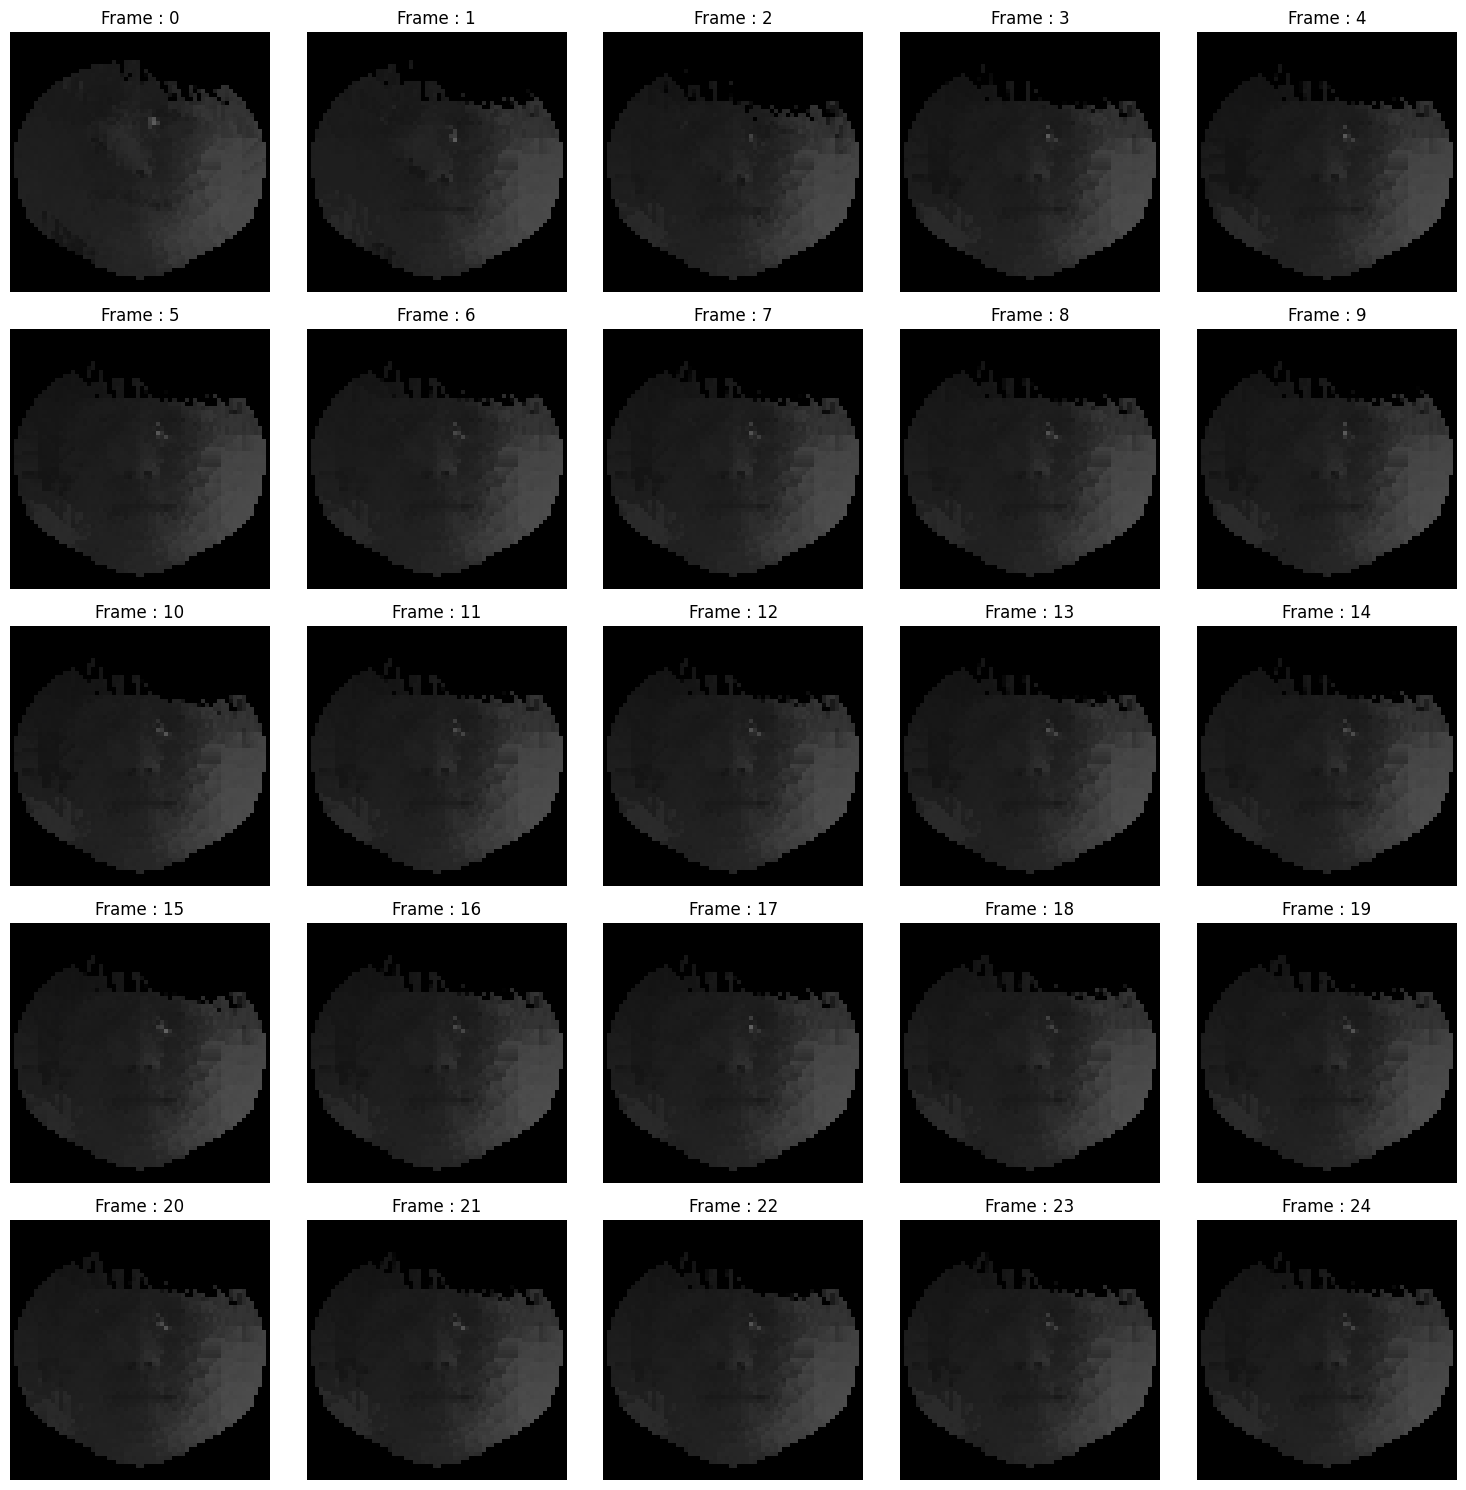

In [163]:
frames_uv_ex = frames_uv[:25]
fig, axes = plt.subplots(5,5, figsize=(15,15))
axes = axes.flatten()

for i, f in enumerate(frames_uv_ex) : 
    axes[i].imshow(f.cpu())
    axes[i].set_title(f"Frame : {i}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

#plt.imshow(frames_uv[0].cpu())

In [120]:
import torch
import torch.nn.functional as F
import numpy as np
from torch import Tensor
from scipy.spatial import Delaunay
from typing import Tuple

class BatchUVAngleMasker:
    """
    Batch-optimized Surface Orientation Masker.
    
    [핵심]
    - Scipy Loop 제거: 느린 griddata 대신 GPU 행렬 연산으로 보간합니다.
    - Face Normal -> Vertex Normal -> Pixel Normal 보간 과정을 배치로 처리합니다.
    """

    def __init__(
        self,
        faces: np.ndarray,
        landmarks_uv: np.ndarray, 
        output_size: int = 64 ,
        camera_normal: Tuple[float, float, float] = (0.0, 0.0, -1.0),
        device: str = "cuda",
        eps: float = 1e-12,
    ) -> None:
        self.device = torch.device(device)
        self.faces = torch.tensor(faces, dtype=torch.long, device=self.device) # (F, 3)
        self.output_size = output_size
        self.eps = eps
        
        # 카메라 벡터 정규화
        cam = torch.tensor(camera_normal, dtype=torch.float32, device=self.device)
        self.cam = cam / torch.clamp(torch.norm(cam), min=eps)

        # Interpolation 가중치 미리 계산 (Warper와 동일)
        self._precompute_interpolation(landmarks_uv, output_size)

    def _precompute_interpolation(self, uv_points: np.ndarray, size: int):
        """Vertices의 값을 UV 픽셀로 보간하기 위한 가중치 계산"""
        if torch.is_tensor(uv_points):
            uv_points = uv_points.detach().cpu().numpy()
            
        y, x = np.meshgrid(np.linspace(0, 1, size), np.linspace(0, 1, size), indexing='ij')
        grid_points = np.stack([x.ravel(), y.ravel()], axis=-1)

        tri = Delaunay(uv_points)
        simplex_indices = tri.find_simplex(grid_points)
        
        valid_mask = simplex_indices != -1
        valid_simplices = simplex_indices[valid_mask]
        valid_grid_points = grid_points[valid_mask]

        transform = tri.transform[valid_simplices, :2]
        offset = tri.transform[valid_simplices, 2]
        diff = valid_grid_points - offset
        
        c = np.einsum('nij,nj->ni', transform, diff)
        weights = np.c_[1 - c[:, 0] - c[:, 1], c[:, 0], c[:, 1]]

        # GPU Tensor 저장
        self.pixel_v_indices = torch.tensor(tri.simplices[valid_simplices], dtype=torch.long, device=self.device)
        self.pixel_weights = torch.tensor(weights, dtype=torch.float32, device=self.device).unsqueeze(1) # (Valid, 1, 3)
        self.valid_mask = torch.tensor(valid_mask, dtype=torch.bool, device=self.device)
        self.H, self.W = size, size

    def __call__(
        self,
        frames_uv: Tensor,            # (B, H, W, C)
        landmarks_xyz: Tensor,        # (B, V, 3) - Valid Only
        degree_threshold: float = 60.0,
    ) -> Tensor:
        """
        Args:
            frames_uv: Warped UV frames.
            landmarks_xyz: 3D landmarks corresponding to the frames.
        """
        B = landmarks_xyz.shape[0]
        if landmarks_xyz.device != self.device:
            landmarks_xyz = landmarks_xyz.to(self.device)

        # 1. Face Normal 계산 (Batch Cross Product)
        v = landmarks_xyz[:, self.faces, :] # (B, F, 3, 3)
        e1 = v[:, :, 1] - v[:, :, 0]
        e2 = v[:, :, 2] - v[:, :, 0]
        
        face_normals = torch.cross(e1, e2, dim=-1) # (B, F, 3)
        
        # 2. Vertex Normal 누적 (Batch Scatter Add)
        vertex_normals = torch.zeros_like(landmarks_xyz)
        
        # 각 Face의 Normal을 구성 Vertex에 더해줌
        for i in range(3):
            indices = self.faces[:, i] # (F,)
            # (B, F, 3) -> (B, V, 3) 로 인덱스에 맞춰 더함
            vertex_normals.index_add_(1, indices, face_normals)
            
        vertex_normals = F.normalize(vertex_normals, p=2, dim=-1, eps=self.eps)

        # 3. 카메라와의 각도(Cosine) 계산
        # (B, V, 3) @ (3,) -> (B, V)
        cos_vals_verts = torch.matmul(vertex_normals, self.cam) 

        # 4. 픽셀로 값 보간 (Matrix Multiplication)
        # Vertex 값 Gather: (B, V) -> (B, Valid_Px, 3)
        batch_vals = cos_vals_verts[:, self.pixel_v_indices]
        
        # 가중치 적용: (1, Valid_Px, 1, 3) @ (B, Valid_Px, 3, 1) -> (B, Valid_Px)
        pixel_vals = torch.matmul(
            self.pixel_weights, 
            batch_vals.unsqueeze(-1)
        ).squeeze(-1).squeeze(-1)

        # 5. Mask 생성 (Thresholding)
        cos_threshold = np.cos(np.deg2rad(degree_threshold))
        
        # Cosine > Threshold (덜 기울어짐) -> True (유지)
        keep_mask_pixels = (pixel_vals >= cos_threshold)
        
        # 전체 이미지로 확장
        batch_valid_mask = self.valid_mask.unsqueeze(0).expand(B, -1) # (B, HW)
        final_mask_flat = torch.zeros((B, self.H * self.W), dtype=torch.bool, device=self.device)
        
        # 유효 영역에 값 채우기
        final_mask_flat[batch_valid_mask] = keep_mask_pixels.reshape(-1)
        
        # (B, H, W, 1) 브로드캐스팅용 shape
        final_mask = final_mask_flat.view(B, self.H, self.W).unsqueeze(-1)

        # 6. 마스킹 적용 (각도 안 맞으면 0)
        return frames_uv * final_mask.float()

In [317]:
# 1. Masker 초기화 (한 번만 수행)
# faces와 landmarks_uv는 용량이 작으므로 초기화 시 GPU에 올려도 괜찮습니다.
masker = BatchUVAngleMasker(
    detector.mesh_faces, 
    detector.landmarks_uv, 
    device=device
)

# 2. 데이터 준비
# frames_uv는 직전 단계 결과물이므로 CPU에 있을 것입니다.
# landmarks_xyz_valid는 GPU에 있더라도 슬라이싱하면 GPU 메모리를 크게 먹지 않습니다.
num_frames = frames_uv.shape[0]
batch_size = 64  # 앞서 성공했던 batch_size와 동일하게 맞추는 것을 추천합니다.
frames_masked_list = []

print(f"Starting Surface Orientation Masking... Total: {num_frames} frames")

# 3. 배치 루프 실행
with torch.no_grad():  # 그래디언트 계산 방지 (메모리 절약 필수)
    for i in tqdm(range(0, num_frames, batch_size), desc="Masking Batches"):
        
        # --- A. 데이터 슬라이싱 및 GPU 이동 ---
        # 1) UV 프레임: CPU -> GPU
        b_frames_uv = frames_uv[i : i + batch_size].to(device)
        
        # 2) 3D 랜드마크: (이미 GPU라면 슬라이싱만, CPU라면 이동)
        # 만약 landmarks_xyz_valid가 GPU 텐서라면 .to(device)는 생략해도 됩니다.
        b_landmarks_xyz = landmarks_xyz_valid[i : i + batch_size]
        if not b_landmarks_xyz.is_cuda:
            b_landmarks_xyz = b_landmarks_xyz.to(device)
            
        # --- B. 마스킹 수행 ---
        # 내부에서 Normal 계산 -> 각도 계산 -> 마스킹 적용
        b_masked_gpu = masker(b_frames_uv, b_landmarks_xyz, degree_threshold=60.0)
        
        # --- C. 결과 저장 및 메모리 정리 ---
        # 결과물을 즉시 CPU로 내립니다.
        frames_masked_list.append(b_masked_gpu.cpu())
        
        # 사용한 임시 변수 삭제 (확실한 메모리 해제)
        del b_frames_uv, b_landmarks_xyz, b_masked_gpu
        
        # 주기적인 캐시 비우기
        if i % (batch_size * 5) == 0:
            torch.cuda.empty_cache()

# 4. 결과 통합
frames_uv_masked = torch.cat(frames_masked_list, dim=0)

print(f"✅ 마스킹 완료!")
print(f"Final Masked Shape: {frames_uv_masked.shape}") # [T, 64, 64, C]

/tmp/ipykernel_1770558/1770348471.py:27: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.faces = torch.tensor(faces, dtype=torch.long, device=self.device) # (F, 3)


Starting Surface Orientation Masking... Total: 105332 frames


Masking Batches: 100%|██████████| 1646/1646 [00:11<00:00, 138.01it/s]


✅ 마스킹 완료!
Final Masked Shape: torch.Size([105332, 64, 64, 3])


In [321]:
frames_uv_masked = frames_uv_masked.detach().cpu().numpy()

frames_uv_masked_final = np.zeros((num_frames_original , 64, 64, 3), dtype=np.float32)

frames_uv_masked_final[valid_mask] = frames_uv_masked 

print(f" 최종결과 : {frames_uv_masked_final.shape}")


AttributeError: 'numpy.ndarray' object has no attribute 'detach'

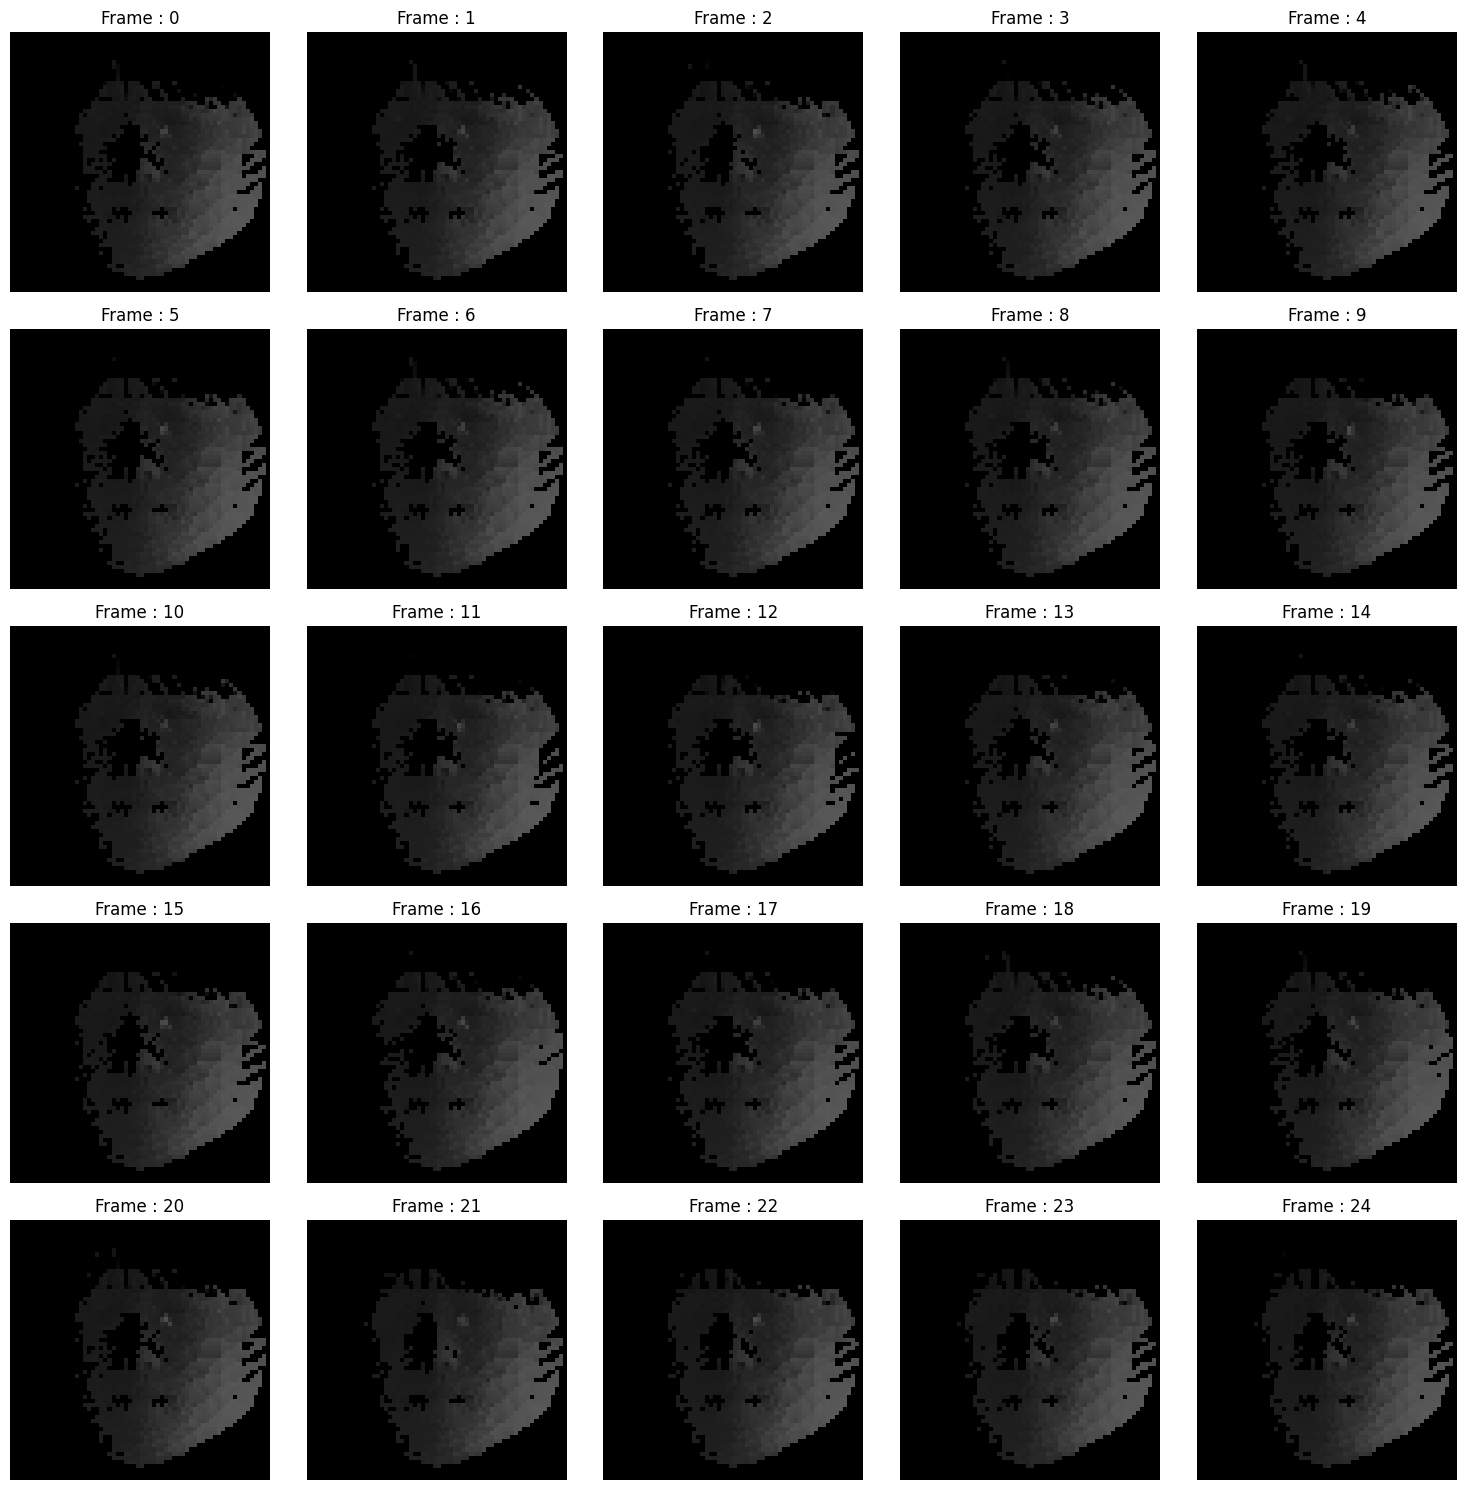

In [169]:
frames_uv_masked_ex = frames_uv_masked_final[1000:1025]
fig, axes = plt.subplots(5,5, figsize=(15,15))
axes = axes.flatten()

for i, f in enumerate(frames_uv_masked_ex) : 
    axes[i].imshow(f)
    axes[i].set_title(f"Frame : {i}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

#plt.imshow(frames_uv_masked[0].cpu())

In [324]:
## save final data
preprocess_result_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/preprocess_result'
result_for_saving = frames_uv_masked_final[:, :, :, 0]

if result_for_saving.dtype == np.float64 :
    result_for_saving = result_for_saving.astype(np.float32)
    print("자료형 변환완료 : float64 -> float32 ")     

base_dirrr = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/videos/'
people11 = sorted([f for f in os.listdir(base_dirrr)])
fil_nam = f'{people11[subject_number]}.h5'

finall_dir = os.path.join(preprocess_result_dir, fil_nam)

byte_size = result_for_saving.nbytes

# 2. MB, GB 단위로 변환
mb_size = byte_size / (1024 ** 2)
gb_size = byte_size / (1024 ** 3)

print(f"데이터 타입: {result_for_saving.dtype}")
print(f"전체 요소 개수: {result_for_saving.size:,} 개")
print(f"메모리 용량: {mb_size:.2f} MB ({gb_size:.2f} GB)")

try : 
    with h5py.File( finall_dir, 'w') as f :
        dset = f.create_dataset(
            'nir_uv_data',
            data = result_for_saving,
            compression = 'gzip',
            compression_opts = 4
        )
        dset.attrs['subject_id'] = people11[subject_number]
        dset.attrs['fps'] = 30
    

        mask_dset = f.create_dataset(
            'valid_mask',
            data = valid_mask, # 가지고 계신 boolean 리스트/배열
            compression = 'gzip',
            compression_opts = 4
        )
        mask_dset.attrs['fail_rate'] = landmark_success_rate

        print(f"✅ [성공] {finall_dir} 경로에 저장 완료!")

except Exception as e : 
    print(f"❌ [오류] 저장 중 문제가 발생했습니다: {e}")



자료형 변환완료 : float64 -> float32 
데이터 타입: float32
전체 요소 개수: 441,249,792 개
메모리 용량: 1683.23 MB (1.64 GB)
✅ [성공] /nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/preprocess_result/A001_20250609.h5 경로에 저장 완료!


In [330]:
with h5py.File(finall_dir, 'r') as f_r:
    # 데이터셋 키(key) 확인 (파일 안에 어떤 데이터셋이 있는지 모를 때)
    print("Keys in H5 file:", list(f_r.keys()))
    print(f_r['nir_uv_data'].attrs['fps'])

Keys in H5 file: ['nir_uv_data']
30


# roi 설정 및 픽셀 intensity 변화추이 관찰

## 랜드마크 추출안되는 프레임 확인

[  2411   2412   2413 ... 103801 103807 103812]


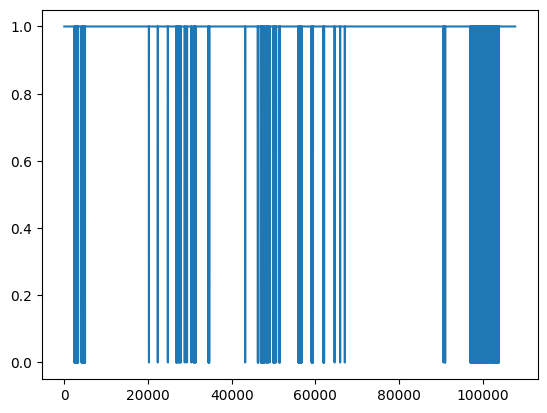

In [170]:
failed_indices = np.where(valid_mask == False)[0]
print(failed_indices)
plt.plot(valid_mask)

(107727, 220, 350, 3)


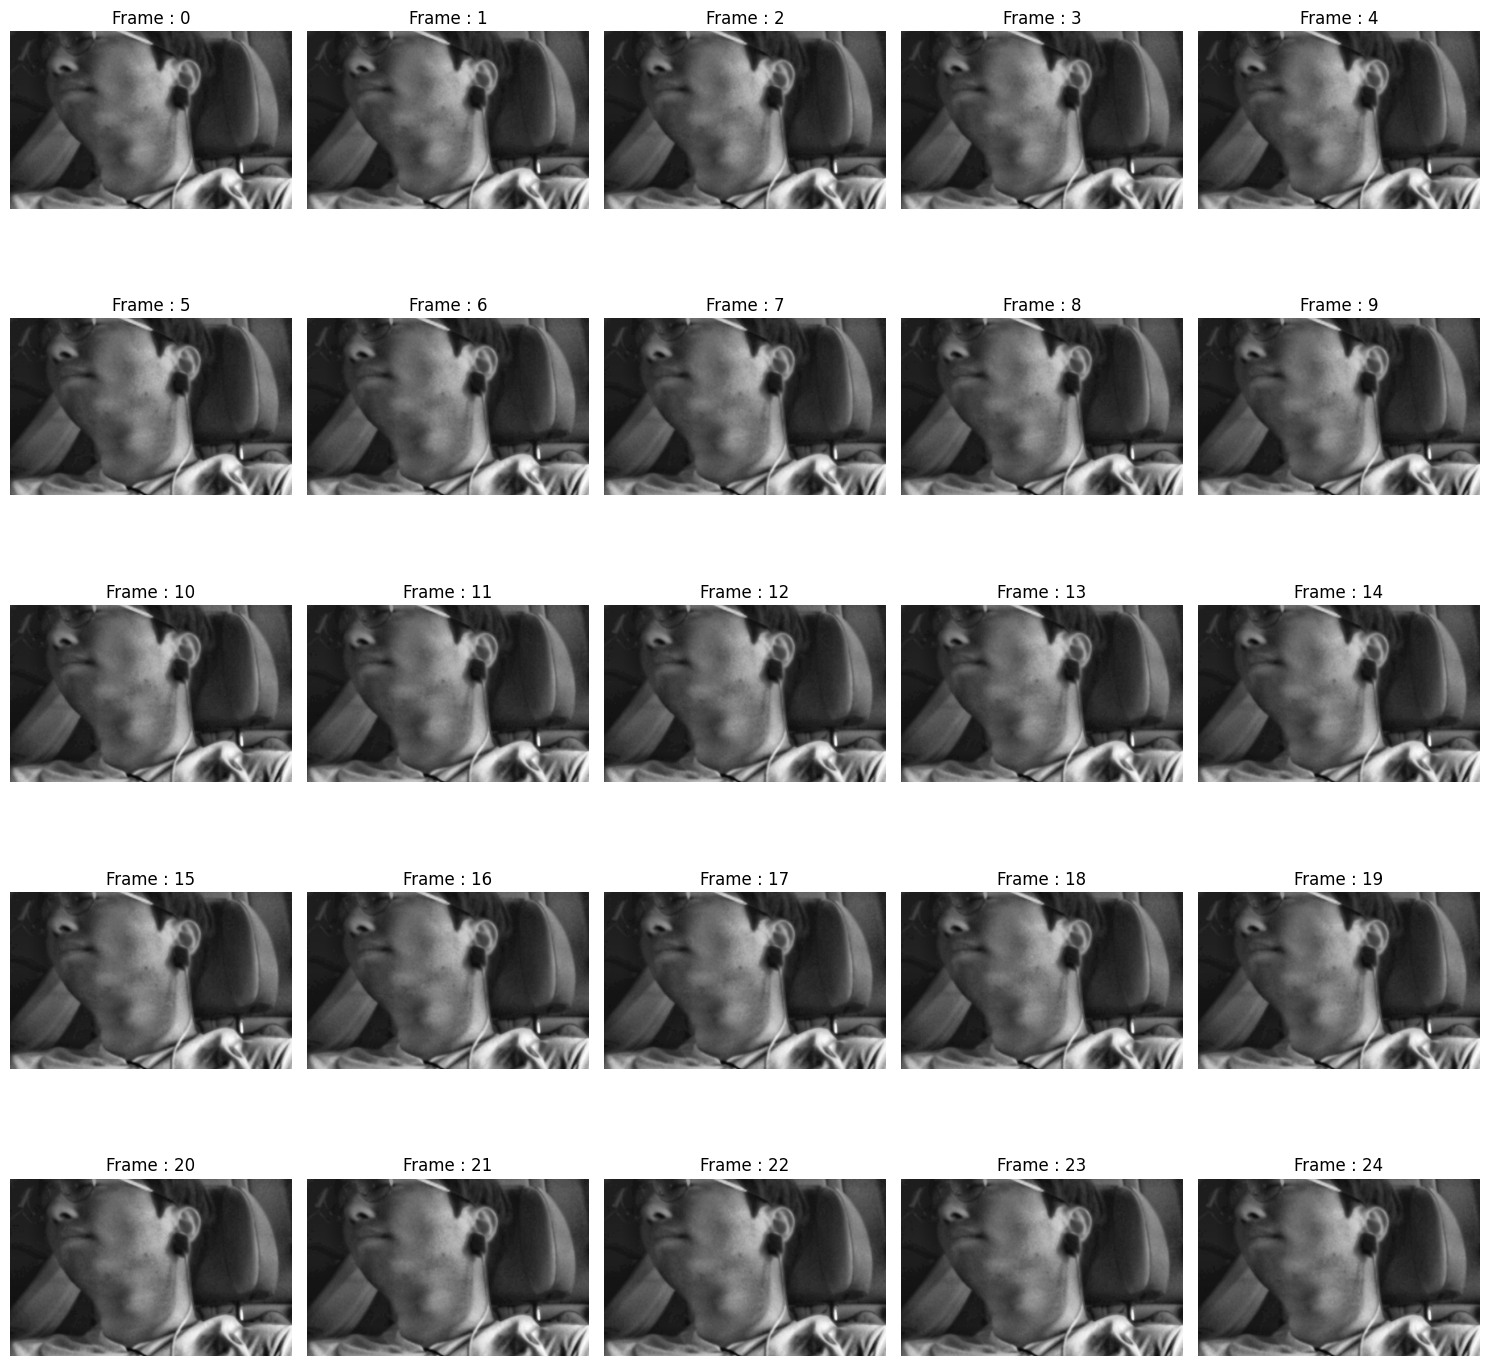

In [182]:
print(frames_xy.shape)
failed_i = failed_indices[100:125]
f_ex = frames_clahe[failed_i]
fig, axes = plt.subplots(5,5, figsize=(15,15)) #fig 가 전체 사진 , axes 가 subplot들 각각 한 칸
axes = axes.flatten()

for i, f in enumerate(f_ex) : 
    axes[i].imshow(f)
    axes[i].set_title(f"Frame : {i}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

구간길이별 개수

랜드마크 실패구간 총 개수 : 1727


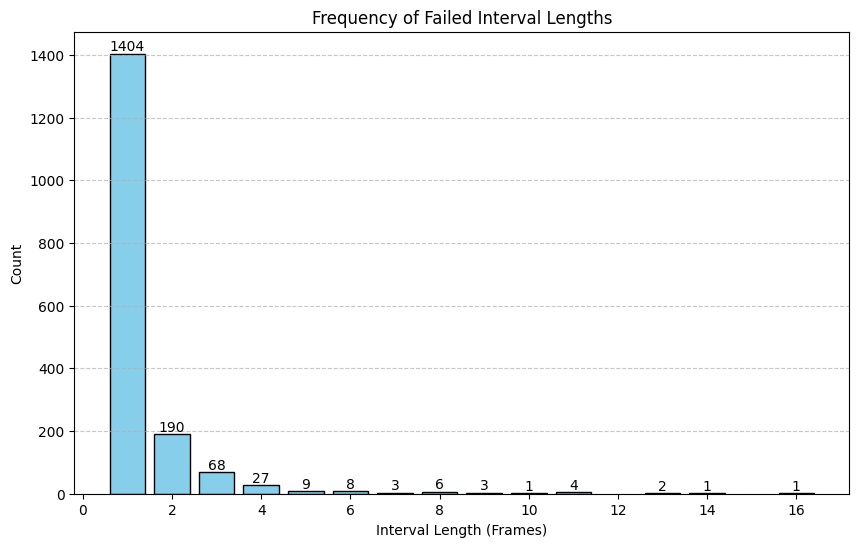

In [181]:
from collections import Counter

failed_intervals = []
fail_list = []

for i in range(len(failed_indices)) :
    fail_list.append(failed_indices[i])
    if  i == len(failed_indices)-1 or failed_indices[i]+1 != failed_indices[i+1] :
        failed_intervals.append(fail_list)
        fail_list = []
    else : 
        continue        

failed_interaval_size = []
for interval in failed_intervals :
    failed_interaval_size.append(len(interval))

print(f'랜드마크 실패구간 총 개수 : {len(failed_intervals)}')    

# 1. 구간 길이별로 개수 세기 (예: {1: 50번, 2: 10번, ...})
length_counts = Counter(failed_interaval_size)

# 2. X축(길이) 기준으로 정렬 (1, 2, 3, 4 ... 순서대로)
sorted_counts = sorted(length_counts.items()) 

# 3. 데이터 분리
lengths, frequencies = zip(*sorted_counts)

# 4. 막대그래프 그리기
plt.figure(figsize=(10, 6))
bar_plot = plt.bar(lengths, frequencies, color='skyblue', edgecolor='black')

# 5. 그래프 꾸미기
plt.title("Frequency of Failed Interval Lengths") # 실패 구간 길이별 빈도
plt.xlabel("Interval Length (Frames)")            # 구간 길이 (프레임 수)
plt.ylabel("Count")                               # 발생 횟수
plt.grid(axis='y', linestyle='--', alpha=0.7)

# (선택) 막대 위에 숫자 표시
for rect in bar_plot:
    height = rect.get_height()
    plt.text(rect.get_x() + rect.get_width()/2.0, height, '%d' % int(height), ha='center', va='bottom')

plt.show()

## rppg 추출

(107727, 64, 64, 3)


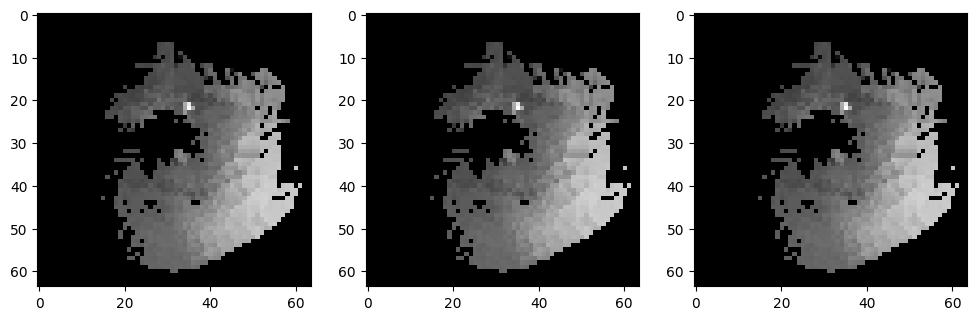

In [185]:
print(frames_uv_masked_final.shape)
a = frames_uv_masked[0,:,:,0]
b = frames_uv_masked[0,:,:,1]
c = frames_uv_masked[0,:,:,2]

plt.figure(figsize = (12,6))


plt.subplot(1,3,1)
plt.imshow(a, cmap ='gray')

plt.subplot(1,3,2)
plt.imshow(b, cmap ='gray')

plt.subplot(1,3,3)
plt.imshow(c, cmap ='gray')


상위 1위 좌표: UV(23, 49), 분산값: 0.035013
상위 2위 좌표: UV(25, 48), 분산값: 0.031510
상위 3위 좌표: UV(26, 48), 분산값: 0.029791
상위 4위 좌표: UV(24, 49), 분산값: 0.023461
상위 5위 좌표: UV(26, 49), 분산값: 0.022557


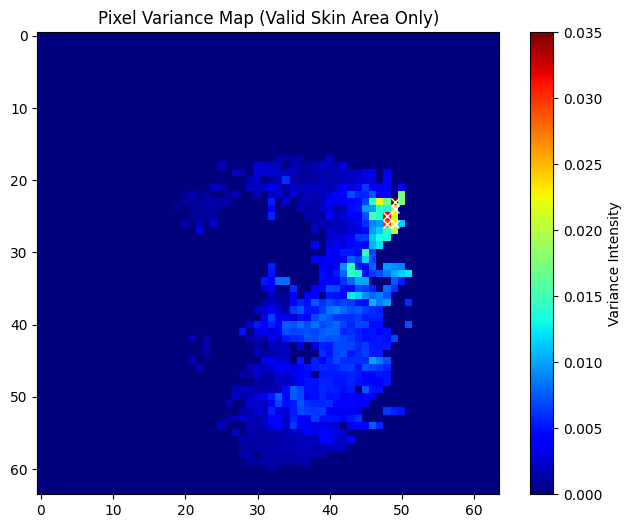

In [236]:
#얼굴 픽셀중 std가 높은 상위값 추출

# 데이터 준비 (T, H, W) 형태라고 가정
data = frames_uv_masked_final[:, :, :, 0]  # 0번 채널(NIR) 사용
T, H, W = data.shape

# 1. 픽셀별 가시성 확인 (마스킹된 프레임 제외)
# 2,000프레임 중 1,800프레임(90%) 이상 값이 있는 픽셀만 골라냄 >>> 수정해야됨 
visibility = (data > 0).sum(axis=0)
valid_maskk = visibility > (T * 0.90)

# 2. 유효 픽셀들의 분산(Variance) 계산
# 마스킹된 영역은 계산에서 제외하기 위해 valid_mask를 곱해줌
pixel_variance = np.var(data, axis = 0) * valid_maskk

# 3. 변동성 상위 5개 좌표 찾기
flat_indices = np.argsort(pixel_variance.flatten())[::-1]
top_coords = []
for i in range(5):
    idx = flat_indices[i]
    y, x = divmod(idx, W)
    top_coords.append((y, x))
    print(f"상위 {i+1}위 좌표: UV({y}, {x}), 분산값: {pixel_variance[y, x]:.6f}")

# 4. 변동성 지도(Heatmap) 시각화
plt.figure(figsize=(8, 6))
plt.imshow(pixel_variance, cmap='jet')
plt.colorbar(label='Variance Intensity')
for y, x in top_coords:
    plt.plot(x, y, 'wx')  # 상위 좌표 흰색 X로 표시
plt.title("Pixel Variance Map (Valid Skin Area Only)")
plt.show()

top4_coor = []
coor_rc = []
for t in range(4) : 
    for j in range(2) :
        coor_rc.append(top_coords[t][j])
    top4_coor.append(coor_rc)
    coor_rc = []
    

#top_std_r , top_std_c = top_coords[0][0], top_coords[0][1]


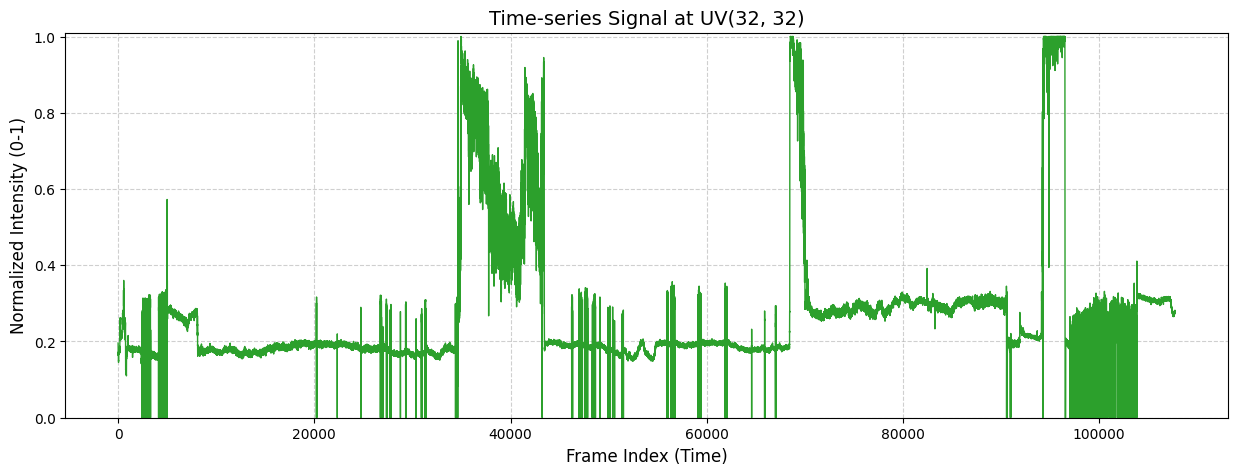

In [200]:
# test at one point
reg = frames_uv_masked_final[:, top_std_r , top_std_c ,0]
reg.shape
reg = reg

# 2. 간단한 시계열 플롯 생성
plt.figure(figsize=(15, 5))
plt.plot(reg, color='#2ca02c', linewidth=1) # rPPG 시각화에 자주 쓰이는 초록 계열

# 3. 그래프 정보 설정
plt.title("Time-series Signal at UV(32, 32)", fontsize=14)
plt.xlabel("Frame Index (Time)", fontsize=12)
plt.ylabel("Normalized Intensity (0-1)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# 4. y축 범위 자동 최적화 (미세한 변화를 보기 위함)
# 만약 정규화된 값의 변화가 너무 작다면 이 부분에서 파형이 뚜렷해집니다.
plt.ylim(reg.min() * 0.99, reg.max() * 1.01) 

plt.show()

(107727,)


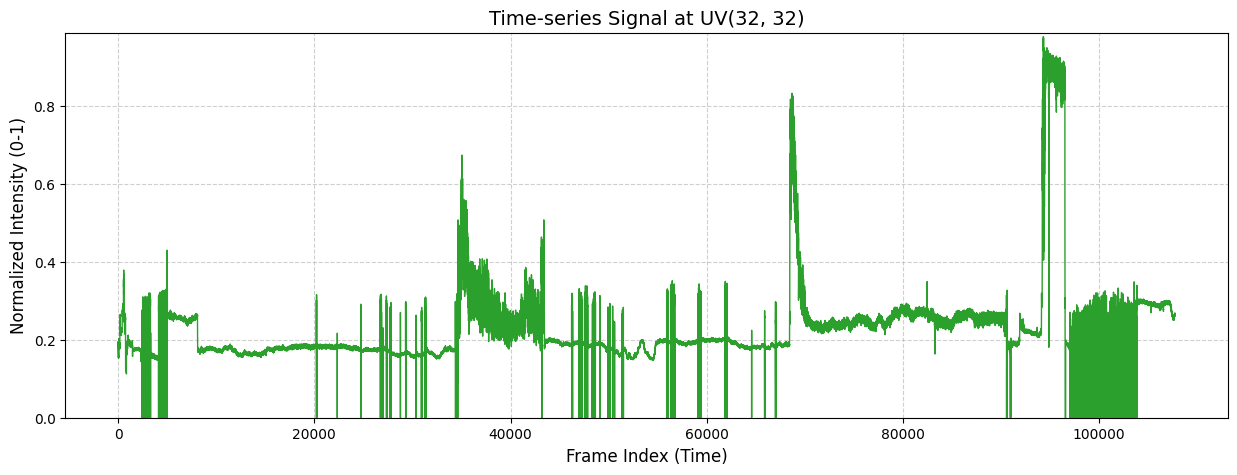

(107727,)


In [245]:
#Test mean 3x3 point
data = frames_uv_masked_final[:, :, :, 0]  # 0번 채널(NIR) 사용
r,c = top_std_r, top_std_c
box = 5
half = box//2

roi_pixels = data[:, r-1 : r + 2, c-1 : c + 2]
nonzero_count = (roi_pixels > 0).sum(axis=(1, 2))
avg_sig = roi_pixels.sum(axis=(1,2)) / (nonzero_count + 1e-6) # 0으로 나누기 방지

print(avg_sig.shape)

plt.figure(figsize=(15, 5))
plt.plot(avg_sig, color='#2ca02c', linewidth=1) # rPPG 시각화에 자주 쓰이는 초록 계열

# 3. 그래프 정보 설정
plt.title("Time-series Signal at UV(32, 32)", fontsize=14)
plt.xlabel("Frame Index (Time)", fontsize=12)
plt.ylabel("Normalized Intensity (0-1)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# 4. y축 범위 자동 최적화 (미세한 변화를 보기 위함)
# 만약 정규화된 값의 변화가 너무 작다면 이 부분에서 파형이 뚜렷해집니다.
plt.ylim(avg_sig.min() * 0.99, avg_sig.max() * 1.01) 

plt.show()
print(avg_sig.shape)

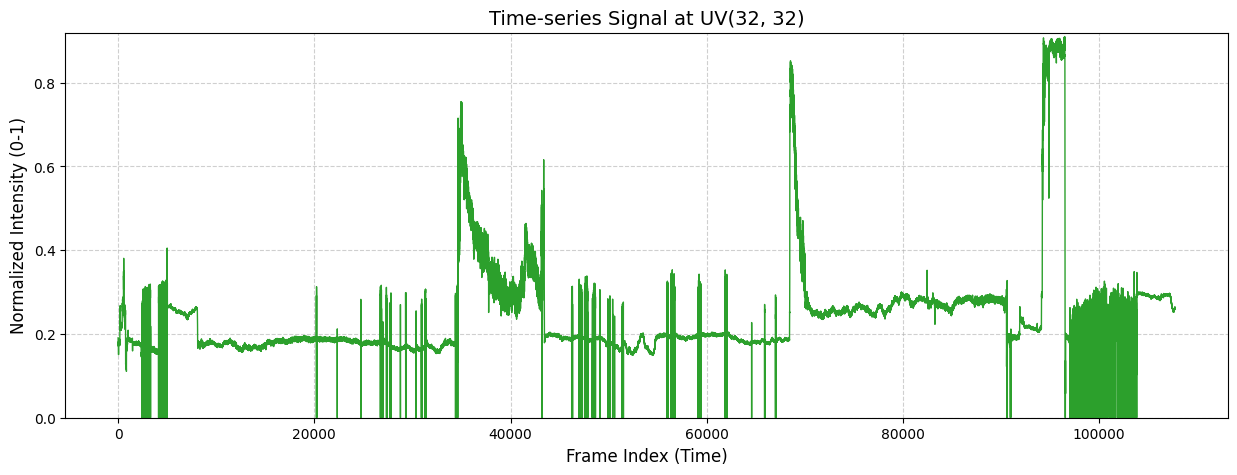

In [244]:
#Test mean 3x3 point by 4 points
data = frames_uv_masked_final[:, :, :, 0]  # 0번 채널(NIR) 사용
avg_sig_sum = np.zeros(107727)

for i in range(len(top4_coor)) :
    coor_t = top4_coor[i]

    r,c = coor_t[0] , coor_t[1]

    roi_pixels = data[:, r-1 : r + 2, c-1 : c + 2]
    nonzero_count = (roi_pixels > 0).sum(axis=(1, 2))
    avg_sig = roi_pixels.sum(axis=(1,2)) / (nonzero_count + 1e-6) # 0으로 나누기 방지
    
    avg_sig_sum += avg_sig

avg_sig_f = avg_sig_sum / len(top4_coor)


plt.figure(figsize=(15, 5))
plt.plot(avg_sig_f, color='#2ca02c', linewidth=1) # rPPG 시각화에 자주 쓰이는 초록 계열

# 3. 그래프 정보 설정
plt.title("Time-series Signal at UV(32, 32)", fontsize=14)
plt.xlabel("Frame Index (Time)", fontsize=12)
plt.ylabel("Normalized Intensity (0-1)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# 4. y축 범위 자동 최적화 (미세한 변화를 보기 위함)
# 만약 정규화된 값의 변화가 너무 작다면 이 부분에서 파형이 뚜렷해집니다.
plt.ylim(avg_sig_f.min() * 0.99, avg_sig_f.max() * 1.01) 

plt.show()

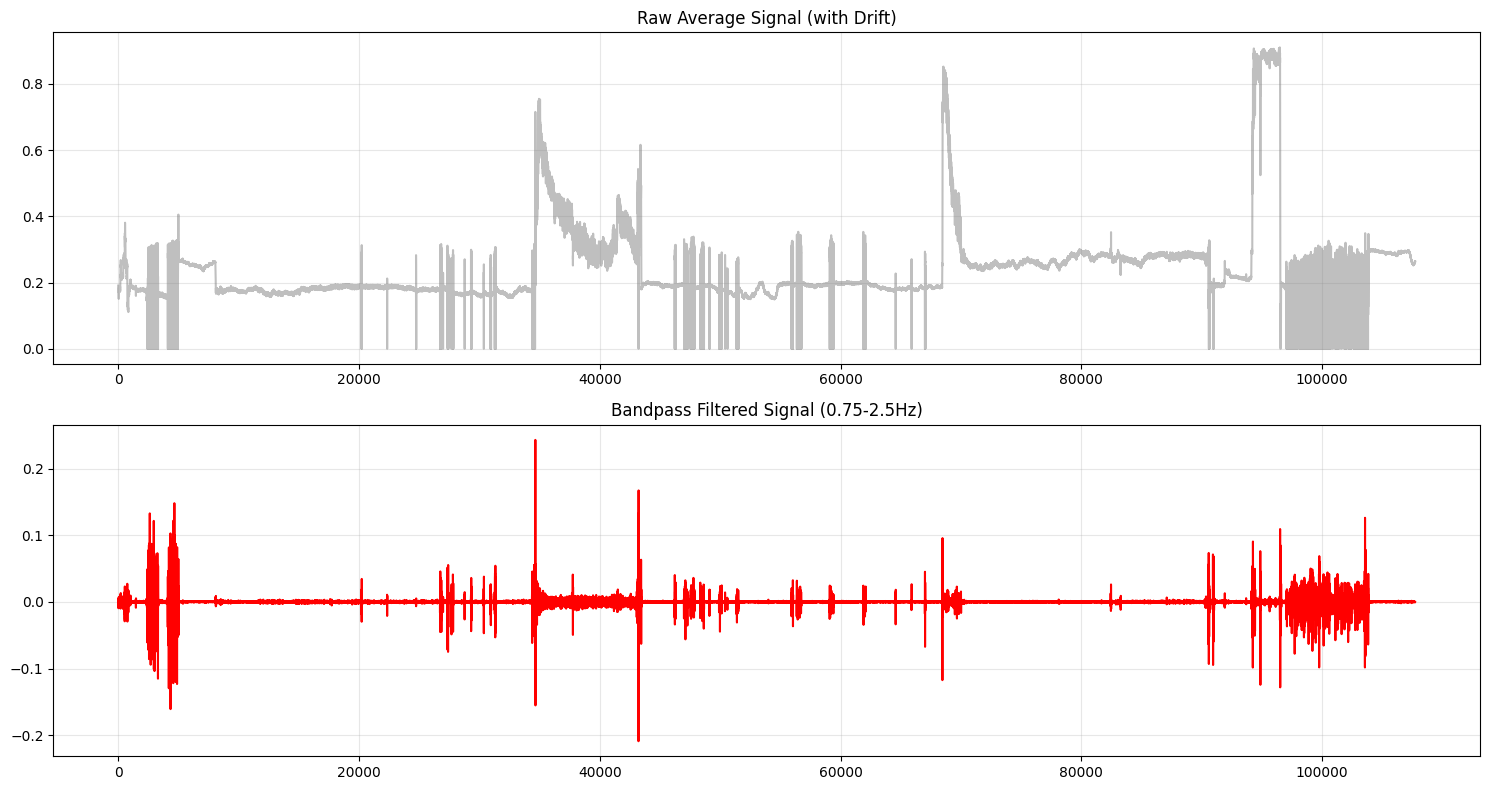

In [247]:
from scipy.signal import butter, filtfilt
from scipy import signal 

def butter_bandpass_filter(data, lowcut, highcut, fs, order=4):
    nyq = 0.5 * fs # 나이퀴스트 주파수
    low = lowcut / nyq
    high = highcut / nyq
    # 버터워스 필터 설계
    b, a = butter(order, [low, high], btype='band')
    # filtfilt를 사용하여 위상 지연 없이 필터링
    y = filtfilt(b, a, data)
    return y

# --- 파라미터 설정 ---
fs = 30.0       # 영상의 FPS (사용자님의 비디오 정보를 꼭 확인하세요)
lowcut = 0.75    # 45 BPM
highcut = 2.5   # 150 BPM

# 1. 텐서를 넘파이 배열로 변환
raw_sig = avg_sig_f

# 2. detrending
detrended_sig = signal.detrend(raw_sig) 

# 3. 필터 적용
filtered_sig = butter_bandpass_filter(detrended_sig, lowcut, highcut, fs, order=2)

# 4. 시각화 (원본 vs 필터링 비교)
plt.figure(figsize=(15, 8))

plt.subplot(2, 1, 1)
plt.plot(raw_sig, color='gray', alpha=0.5)
plt.title("Raw Average Signal (with Drift)")
plt.grid(True, alpha=0.3)

plt.subplot(2, 1, 2)
plt.plot(filtered_sig, color='red')
plt.title(f"Bandpass Filtered Signal ({lowcut}-{highcut}Hz)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## ppg downsampling

In [248]:
# 원본 ppg 
import pandas as pd

#ppg 원본
ppg_orig_dir = '/nasdata2/2yhy/CNA_ours_IRB/edited/final_report_ppg'
people_list_2 = sorted( [k for k in os.listdir(ppg_orig_dir)] )
subject_nnuum = 0
raw_ppg_root = os.path.join(ppg_orig_dir, people_list_2[subject_nnuum])

#비디오 원본
base_dir_1 = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/videos/'
people = sorted([f for f in os.listdir(base_dir_1)])
vp1 = os.path.join(base_dir_1,people[subject_nnuum],'NIR')


### subject 설정
ppg_orig = pd.read_csv(raw_ppg_root)

print(f'원본 ppg 경로 {raw_ppg_root}')
print(f"비디오 경로 : {vp1}")
print(f"ppg 원본 수 {ppg_orig.shape}")
print(f"총 프레임 수 : {len(os.listdir(vp1))} ")
print(f'ppg downsampling후 개수 : {ppg_orig.shape[0] * (30/500)}')

원본 ppg 경로 /nasdata2/2yhy/CNA_ours_IRB/edited/final_report_ppg/A001_250609_cut.csv
비디오 경로 : /nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/videos/A001_20250609/NIR
ppg 원본 수 (1918520, 1)
총 프레임 수 : 107727 
ppg downsampling후 개수 : 115111.2


In [217]:
# 1. 원본 / 설정값
fs_origin = 500
fs_target =30

start_idx = 16667
end_idx = 33333
ppg_segment = ppg_orig
#minute_s = 33.33/60 # 원본영상 분 

# 2. downsampling
#num_samples = int(30*60*(minute_s))
num_samples = num_frames_original
frame_camera = data.shape[0]

ppg_downsampled = signal.resample(ppg_segment, data.shape[0])

# 3. 확인
print(f"다운 샘플링 후 샘플 수 : {ppg_downsampled.shape}")
print(f"원본 영상 프레임 수 : {data.shape[0]}")



다운 샘플링 후 샘플 수 : (107727, 1)
원본 영상 프레임 수 : 107727


## 결과비교

In [268]:
# z normalization to compare with
def z_norm(sig) :
    return( (sig - np.mean(sig)) / np.std(sig) )

rppg_z = z_norm(filtered_sig)
ppg_z = z_norm(butter_bandpass_filter(ppg_downsampled.reshape(-1), lowcut, highcut, fs, order=2))
ppg_z_2 = z_norm(butter_bandpass_filter(ppg_orig.to_numpy().reshape(-1), lowcut, highcut, fs, order=2))

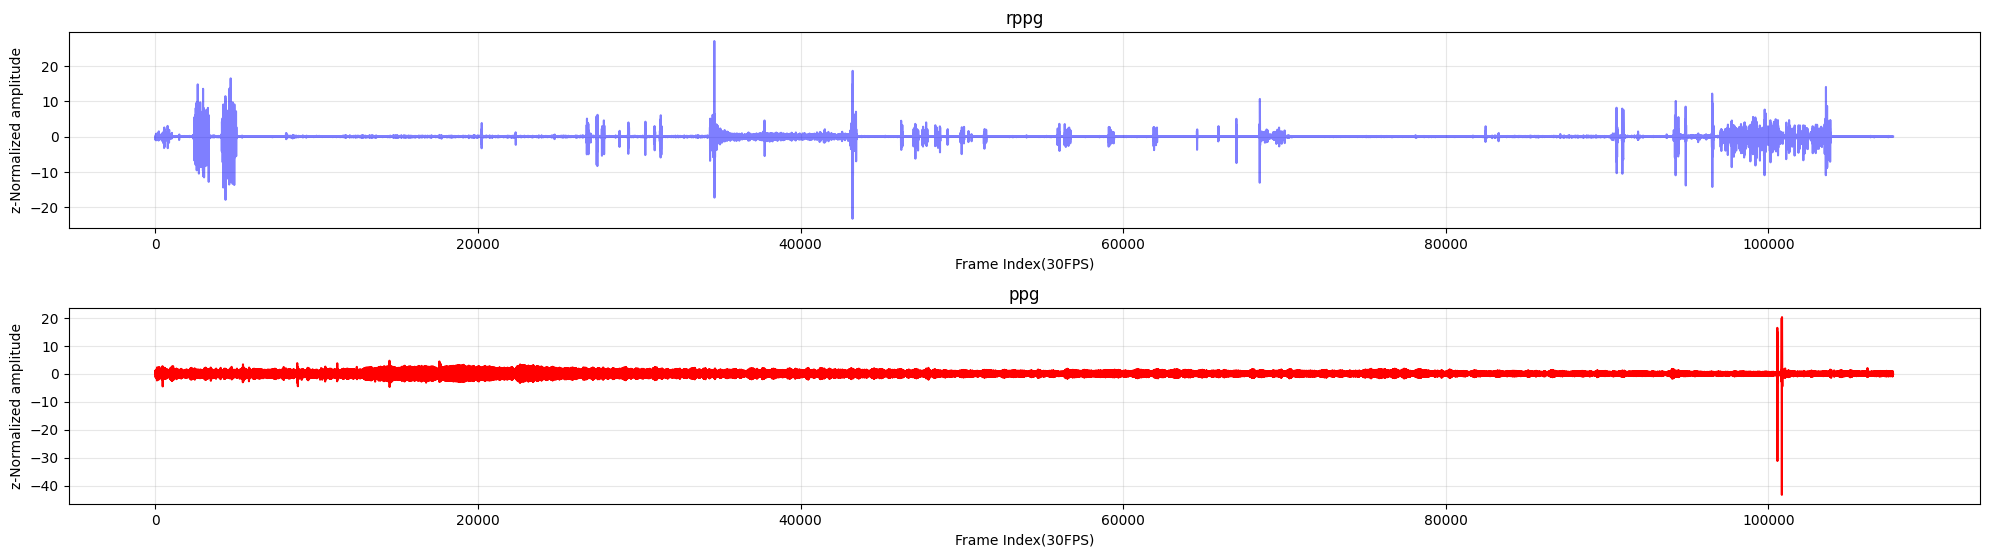

In [251]:
plt.figure(figsize=(20, 8))

plt.subplot(3, 1, 1)
plt.plot(rppg_z, color='blue', alpha=0.5)
plt.title("rppg")
plt.xlabel('Frame Index(30FPS)')
plt.ylabel('z-Normalized amplitude')
plt.grid(True, alpha=0.3)

plt.subplot(3, 1, 2)
plt.plot(ppg_z, color='red')
plt.title(f"ppg")
plt.xlabel('Frame Index(30FPS)')
plt.ylabel('z-Normalized amplitude')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

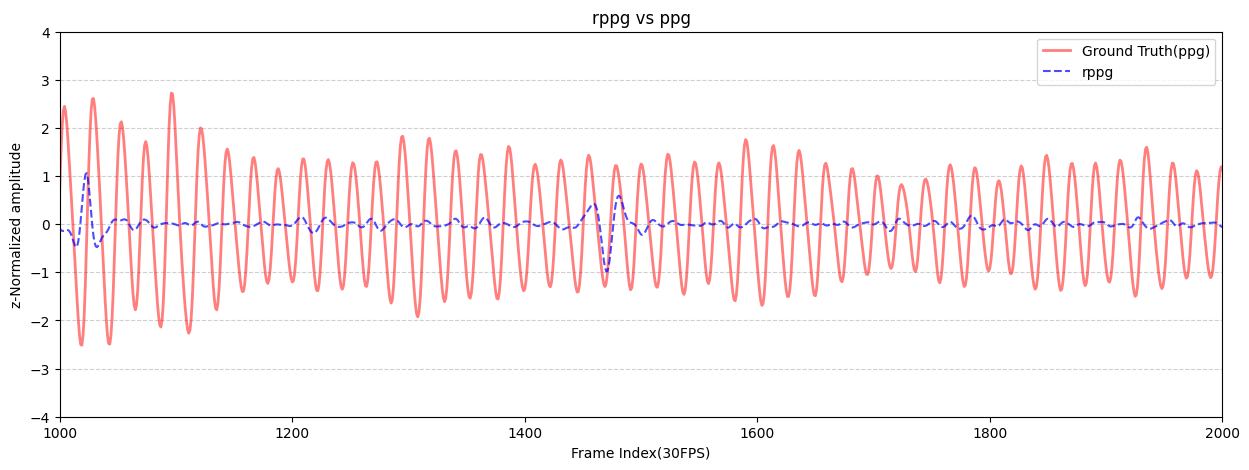

In [269]:
plt.figure(figsize = (15,5))

plt.plot(ppg_z, label ='Ground Truth(ppg)', color = 'red', alpha = 0.5, linewidth = 2)
plt.plot(rppg_z, label = 'rppg', color = 'blue', alpha = 0.7, linestyle = '--')

plt.title('rppg vs ppg')
plt.xlabel('Frame Index(30FPS)')
plt.ylabel('z-Normalized amplitude')
plt.legend(loc = 'upper right')
plt.grid(True, axis='y', linestyle='--', alpha=0.6)

plt.xlim(1000, 2000) ## 특정구간 관찰
plt.ylim(-4,4)
plt.show()

## compare in frequency domain

In [263]:
# signal fft
import numpy as np
from scipy.fft import fft
from scipy import signal
from scipy.signal import butter, filtfilt

def hr_fft(sig, fs, harmonics_removal=True):
    # get heart rate by FFT
    # return both heart rate and PSD

    sig = sig.reshape(-1)
    sig = sig * signal.windows.hann(sig.shape[0])
    sig_f = np.abs(fft(sig))
    low_idx = np.round(0.75 / fs * sig.shape[0]).astype('int')
    high_idx = np.round(2.5 / fs * sig.shape[0]).astype('int')
    sig_f_original = sig_f.copy()
    
    sig_f[:low_idx] = 0
    sig_f[high_idx:] = 0

    peak_idx, _ = signal.find_peaks(sig_f)
    sort_idx = np.argsort(sig_f[peak_idx])
    sort_idx = sort_idx[::-1]

    peak_idx1 = peak_idx[sort_idx[0]]
    peak_idx2 = peak_idx[sort_idx[1]]

    f_hr1 = peak_idx1 / sig.shape[0] * fs
    hr1 = f_hr1 * 60

    f_hr2 = peak_idx2 / sig.shape[0] * fs
    hr2 = f_hr2 * 60
    if harmonics_removal:
        if np.abs(hr1-2*hr2)<10:
            hr = hr2
        else:
            hr = hr1
    else:
        hr = hr1

    x_hr = np.arange(len(sig))/len(sig)*fs*60
    return hr, sig_f_original, x_hr

In [309]:
# Get highest bpm for MAE
ae_list = []

for i in range( 0, data.shape[0], 900) :
    start_idex = i
    end_idex = i + 900

    hr_ppg, psd_ppg, axis_ppg = hr_fft(ppg_z[ start_idex : end_idex ], fs =30)
    hr_rppg, psd_rppg, axis_rppg = hr_fft(rppg_z[ start_idex : end_idex ], fs =30)
    ae = abs(hr_ppg - hr_rppg)
    ae_list.append(ae)


mae = np.mean(ae_list)

print(f"mae : {mae}")

mae : 18.18354066985646


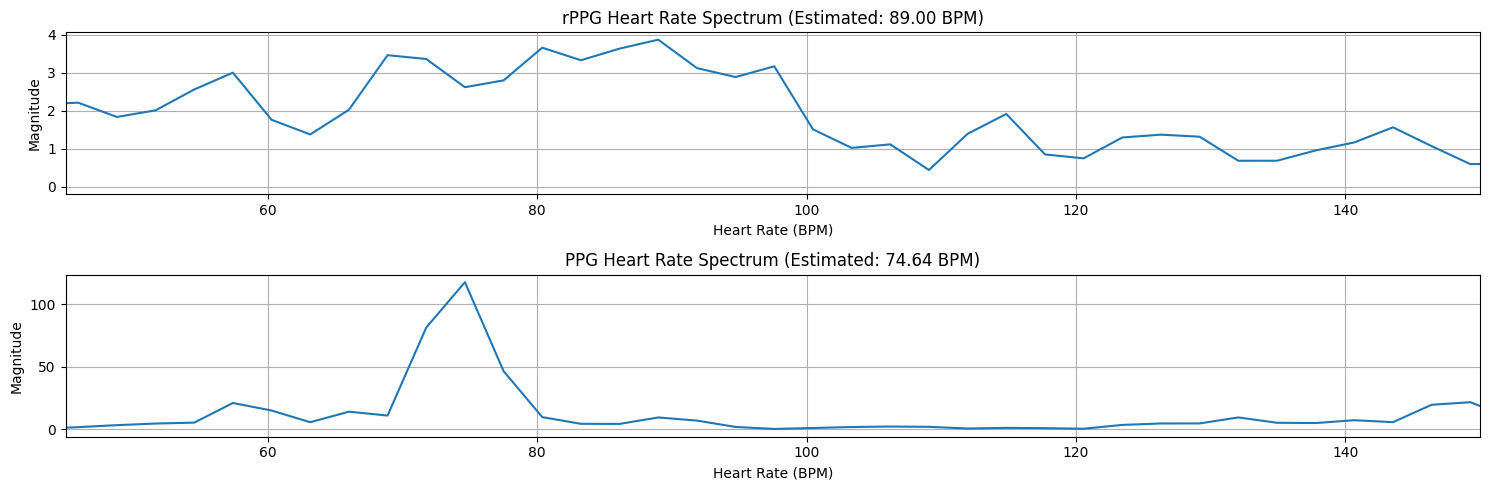

In [310]:
plt.figure(figsize=(15, 5))

plt.subplot(2,1,1)
plt.plot(axis_rppg, psd_rppg) # x축은 bpm_axis(3번째 리턴), y축은 psd(2번째 리턴)
plt.title(f"rPPG Heart Rate Spectrum (Estimated: {hr_rppg:.2f} BPM)")
plt.xlabel("Heart Rate (BPM)")
plt.ylabel("Magnitude")
plt.xlim(45, 150)
plt.grid(True)

plt.subplot(2,1,2)
plt.plot(axis_ppg, psd_ppg) # x축은 bpm_axis(3번째 리턴), y축은 psd(2번째 리턴)
plt.title(f"PPG Heart Rate Spectrum (Estimated: {hr_ppg:.2f} BPM)")
plt.xlabel("Heart Rate (BPM)")
plt.ylabel("Magnitude")
plt.xlim(45, 150)
plt.grid(True)

plt.tight_layout()
plt.show()

# hrv / hr 지표 비교

In [266]:
from scipy.signal import find_peaks
from astropy.timeseries import LombScargle
import neurokit2 as nk


def get_ibi(sig, sig_fps):
    ppg_clean = nk.ppg_clean(sig.copy(), sampling_rate=sig_fps, method='elgendi')
    info = nk.ppg_findpeaks(ppg_clean,sampling_rate=sig_fps)
    peak_loc = info["PPG_Peaks"]
    
    IBI = (peak_loc[1:]-peak_loc[0:-1])/sig_fps
    return IBI

def freq_features(ibi):
    
    def find_highest_peak(sig):
        peak_loc = find_peaks(sig)[0]
        peak_amp = sig[peak_loc]
        highest_peak_loc = np.argmax(peak_amp)
        peak_loc = peak_loc[highest_peak_loc]
        return peak_loc
    
    freq,power = LombScargle(np.cumsum(ibi), ibi).autopower(minimum_frequency=0.01,maximum_frequency=0.51)
    idx_lf = np.where((freq>0.04)*(freq<0.15))
    idx_hf = np.where((freq>0.15)*(freq<0.40))
    
    freq_lf = freq[idx_lf]
    power_lf = np.sum(power[idx_lf])
    peak_loc_lf= find_highest_peak(power[idx_lf])
    
    freq_hf = freq[idx_hf]
    power_hf = np.sum(power[idx_hf])
    peak_loc_hf= find_highest_peak(power[idx_hf])
    
    f_list = {'lf_f' : [], 'hf_f' : [], 'lfnu' : [], 'hfnu' : [], 'lf_hf_ratio' : []}
    f_list['lf_f'].append(freq_lf[peak_loc_lf]) # lf_f
    f_list['hf_f'].append(freq_hf[peak_loc_hf]) # hf_f
    f_list['lfnu'].append(power_lf / (power_lf+power_hf)) # lfnu
    f_list['hfnu'].append(power_hf / (power_lf+power_hf)) # hfnu
    f_list['lf_hf_ratio'].append(power_lf / power_hf) # lf_hf_ratio
    return f_list

In [60]:
ppg_gt = z_norm(butter_bandpass_filter(ppg_segment.to_numpy().reshape(-1), lowcut, highcut, fs, order=2))
ibi_ppg = get_ibi(ppg_gt, sig_fps = 500)
hrv_ppg = freq_features(ibi_ppg)

ibi_rppg = get_ibi(rppg_z, sig_fps = 30)
hrv_rppg = freq_features(ibi_rppg)

print(hrv_ppg)
print(hrv_rppg)

{'lf_f': [0.11835617311492126], 'hf_f': [0.18209509847663968], 'lfnu': [0.27816118926713024], 'hfnu': [0.7218388107328698], 'lf_hf_ratio': [0.38535083613018567]}
{'lf_f': [0.048461538461538466], 'hf_f': [0.1958974358974359], 'lfnu': [0.41698768833646577], 'hfnu': [0.5830123116635343], 'lf_hf_ratio': [0.7152296443734726]}
